# Лабораторная работа 2. Исследовательский анализ данных

**Выполнил:** Моисеев Г. В., группа 4414

**Вариант 16.** Набор данных `drivers.csv`. В методичке 15 вариантов, поэтому номер взят по кругу: 16 → 1, задания варианта 1.

**Цель работы:** изучение связи между признаками двумерного набора данных, визуализация данных.

## 1. Загрузка данных

Используется набор данных `drivers.csv` после предобработки из лабораторной работы 1. Там названия столбцов приведены к одному виду, пропуски в цели поездки заменены на «не определена», удалены поездки с нулевой длительностью, даты переведены в `datetime`, а `TIME` и `PRICE` — в `int64`. Обработанная таблица сохранена в `data/drivers_clean.csv`, поэтому эти шаги здесь не повторяются.

Каждая строка — одна поездка в такси.

| Столбец | Что хранит |
|---|---|
| `START_DATE` | дата и время начала поездки |
| `END_DATE` | дата и время окончания поездки |
| `CATEGORY` | категория поездки: `Business` (деловая) или `Personal` (личная) |
| `START` | место начала поездки |
| `STOP` | место окончания поездки |
| `MILES` | пройденное расстояние, мили |
| `PURPOSE` | цель поездки |
| `TIME` | длительность поездки, минуты |
| `SPEED` | средняя скорость, мили в час |
| `PRICE` | стоимость поездки |

CSV не хранит типы столбцов, поэтому даты при чтении снова переводятся в `datetime` параметром `parse_dates`. Файл читается из папки `data`, если ноутбук запущен локально. В Colab такой папки нет, и тогда файл скачивается из репозитория на GitHub.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%config InlineBackend.figure_format = 'retina'
pd.set_option('display.max_columns', None)
sns.set_theme(style='whitegrid')

DATA_FILE = Path('data/drivers_clean.csv')
DATA_URL = ('https://raw.githubusercontent.com/Echways/ItDA/main/'
            'lab-2/data/drivers_clean.csv')

trips = pd.read_csv(DATA_FILE if DATA_FILE.exists() else DATA_URL,
                    parse_dates=['START_DATE', 'END_DATE'])
trips.head()

,START_DATE,END_DATE,CATEGORY,START,STOP,MILES,PURPOSE,TIME,SPEED,PRICE
0,2016-01-01 21:11:00,2016-01-01 21:17:00,Business,Fort Pierce,Fort Pierce,5.1,Meal/Entertain,6,51.000000,788
1,2016-01-02 01:25:00,2016-01-02 01:37:00,Business,Fort Pierce,Fort Pierce,5.0,не определена,12,25.000000,1237
2,2016-01-02 20:25:00,2016-01-02 20:38:00,Business,Fort Pierce,Fort Pierce,4.8,Errand/Supplies,13,22.153846,1312
3,2016-01-05 17:31:00,2016-01-05 17:45:00,Business,Fort Pierce,Fort Pierce,4.7,Meeting,14,20.142857,1387
4,2016-01-06 14:42:00,2016-01-06 15:49:00,Business,Fort Pierce,West Palm Beach,63.7,Customer Visit,67,57.044776,5376


In [2]:
trips.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1095 entries, 0 to 1094
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   START_DATE  1095 non-null   datetime64[ns]
 1   END_DATE    1095 non-null   datetime64[ns]
 2   CATEGORY    1095 non-null   object        
 3   START       1095 non-null   object        
 4   STOP        1095 non-null   object        
 5   MILES       1095 non-null   float64       
 6   PURPOSE     1095 non-null   object        
 7   TIME        1095 non-null   int64         
 8   SPEED       1095 non-null   float64       
 9   PRICE       1095 non-null   int64         
dtypes: datetime64[ns](2), float64(2), int64(2), object(4)
memory usage: 85.7+ KB


В таблице 1095 строк и 10 столбцов, пропусков нет. Даты прочитались как `datetime64`, `TIME` и `PRICE` — как `int64`: таблица такая же, какой она была в конце предобработки в ЛР1.

In [3]:
trips.describe(include='number')

,MILES,TIME,SPEED,PRICE
count,1095.000000,1095.000000,1095.000000,1095.000000
mean,10.774064,23.385388,27.379427,2092.296804
std,22.009426,27.760654,44.159739,2085.504438
min,0.500000,1.000000,3.917355,412.000000
25%,2.900000,10.000000,15.333333,1087.000000
50%,6.000000,16.000000,21.333333,1539.000000
75%,10.500000,27.500000,28.875000,2401.000000
max,310.300000,336.000000,906.000000,25569.000000


- `MILES` — от 0.5 до 310.3 мили, медиана 6, среднее 10.8.
- `TIME` — от 1 до 336 минут, медиана 16.
- `SPEED` — медиана 21.3 мили в час, но максимум 906 миль/ч. Среднее (27.4) заметно больше медианы, стандартное отклонение — 44.2.
- `PRICE` — от 412 до 25 569, медиана 1539.

## 2. Проверка скорости

В ЛР1 скорость в заданиях не использовалась, и завышенные значения в ней не исправлялись: `TIME` округлён до минут, и у поездок длительностью 1–3 минуты скорость получается слишком большой. Здесь `SPEED` участвует в анализе, поэтому смотрю поездки со скоростью выше 100 миль/ч — для такси это нереально:

In [4]:
too_fast = trips['SPEED'] > 100
columns = ['START', 'STOP', 'MILES', 'TIME', 'SPEED', 'PRICE']
trips.loc[too_fast, columns].sort_values('SPEED')

,START,STOP,MILES,TIME,SPEED,PRICE
335,Raleigh,Cary,32.8,19,103.578947,1771
928,San Francisco,Oakland,9.9,5,118.800000,715
751,Unknown Location,Unknown Location,8.6,4,129.000000,639
759,Unknown Location,Unknown Location,9.4,4,141.000000,640
795,Karachi,Unknown Location,8.0,3,160.000000,564
770,Unknown Location,Unknown Location,5.8,2,174.000000,489
121,Unknown Location,Unknown Location,23.5,8,176.250000,944
778,Unknown Location,Islamabad,10.5,3,210.000000,565
375,Morrisville,Raleigh,7.6,2,228.000000,489
752,Unknown Location,Unknown Location,9.8,2,294.000000,490


Таких поездок 15. Почти у всех длительность 1–8 минут при расстоянии 6–33 мили: например, 15.1 мили за 1 минуту. Длительность записана с ошибкой, а вместе с ней ошибочны скорость и стоимость — стоимость, как видно дальше в разделе 5, считается по времени. Исправить эти значения нечем, поэтому эти 15 поездок удаляю.

In [5]:
trips = trips[~too_fast].reset_index(drop=True)
trips.describe(include='number')

,MILES,TIME,SPEED,PRICE
count,1080.000000,1080.000000,1080.000000,1080.000000
mean,10.624074,23.637963,23.480030,2111.171296
std,21.915269,27.862489,12.485450,2093.207943
min,0.500000,1.000000,3.917355,412.000000
25%,2.800000,10.000000,15.223077,1087.000000
50%,6.000000,17.000000,21.107280,1611.000000
75%,10.500000,28.000000,28.500000,2437.000000
max,310.300000,336.000000,91.500000,25569.000000


После удаления осталось 1080 поездок.

- `MILES` — от 0.5 до 310.3 мили, медиана 6, среднее 10.6. Среднее почти вдвое больше медианы: несколько дальних поездок тянут его вверх.
- `TIME` — от 1 до 336 минут, медиана 17.
- `SPEED` — от 3.9 до 91.5 мили в час, медиана 21.1. Стандартное отклонение упало с 44.2 до 12.5.
- `PRICE` — от 412 до 25 569, медиана 1611, среднее 2111.

## 3. Матрица диаграмм рассеяния

Матрица строится по четырём числовым признакам, точки раскрашены по категории поездки. Подписи осей для этих признаков собраны в словаре `LABELS`, чтобы не повторять их в каждом графике.

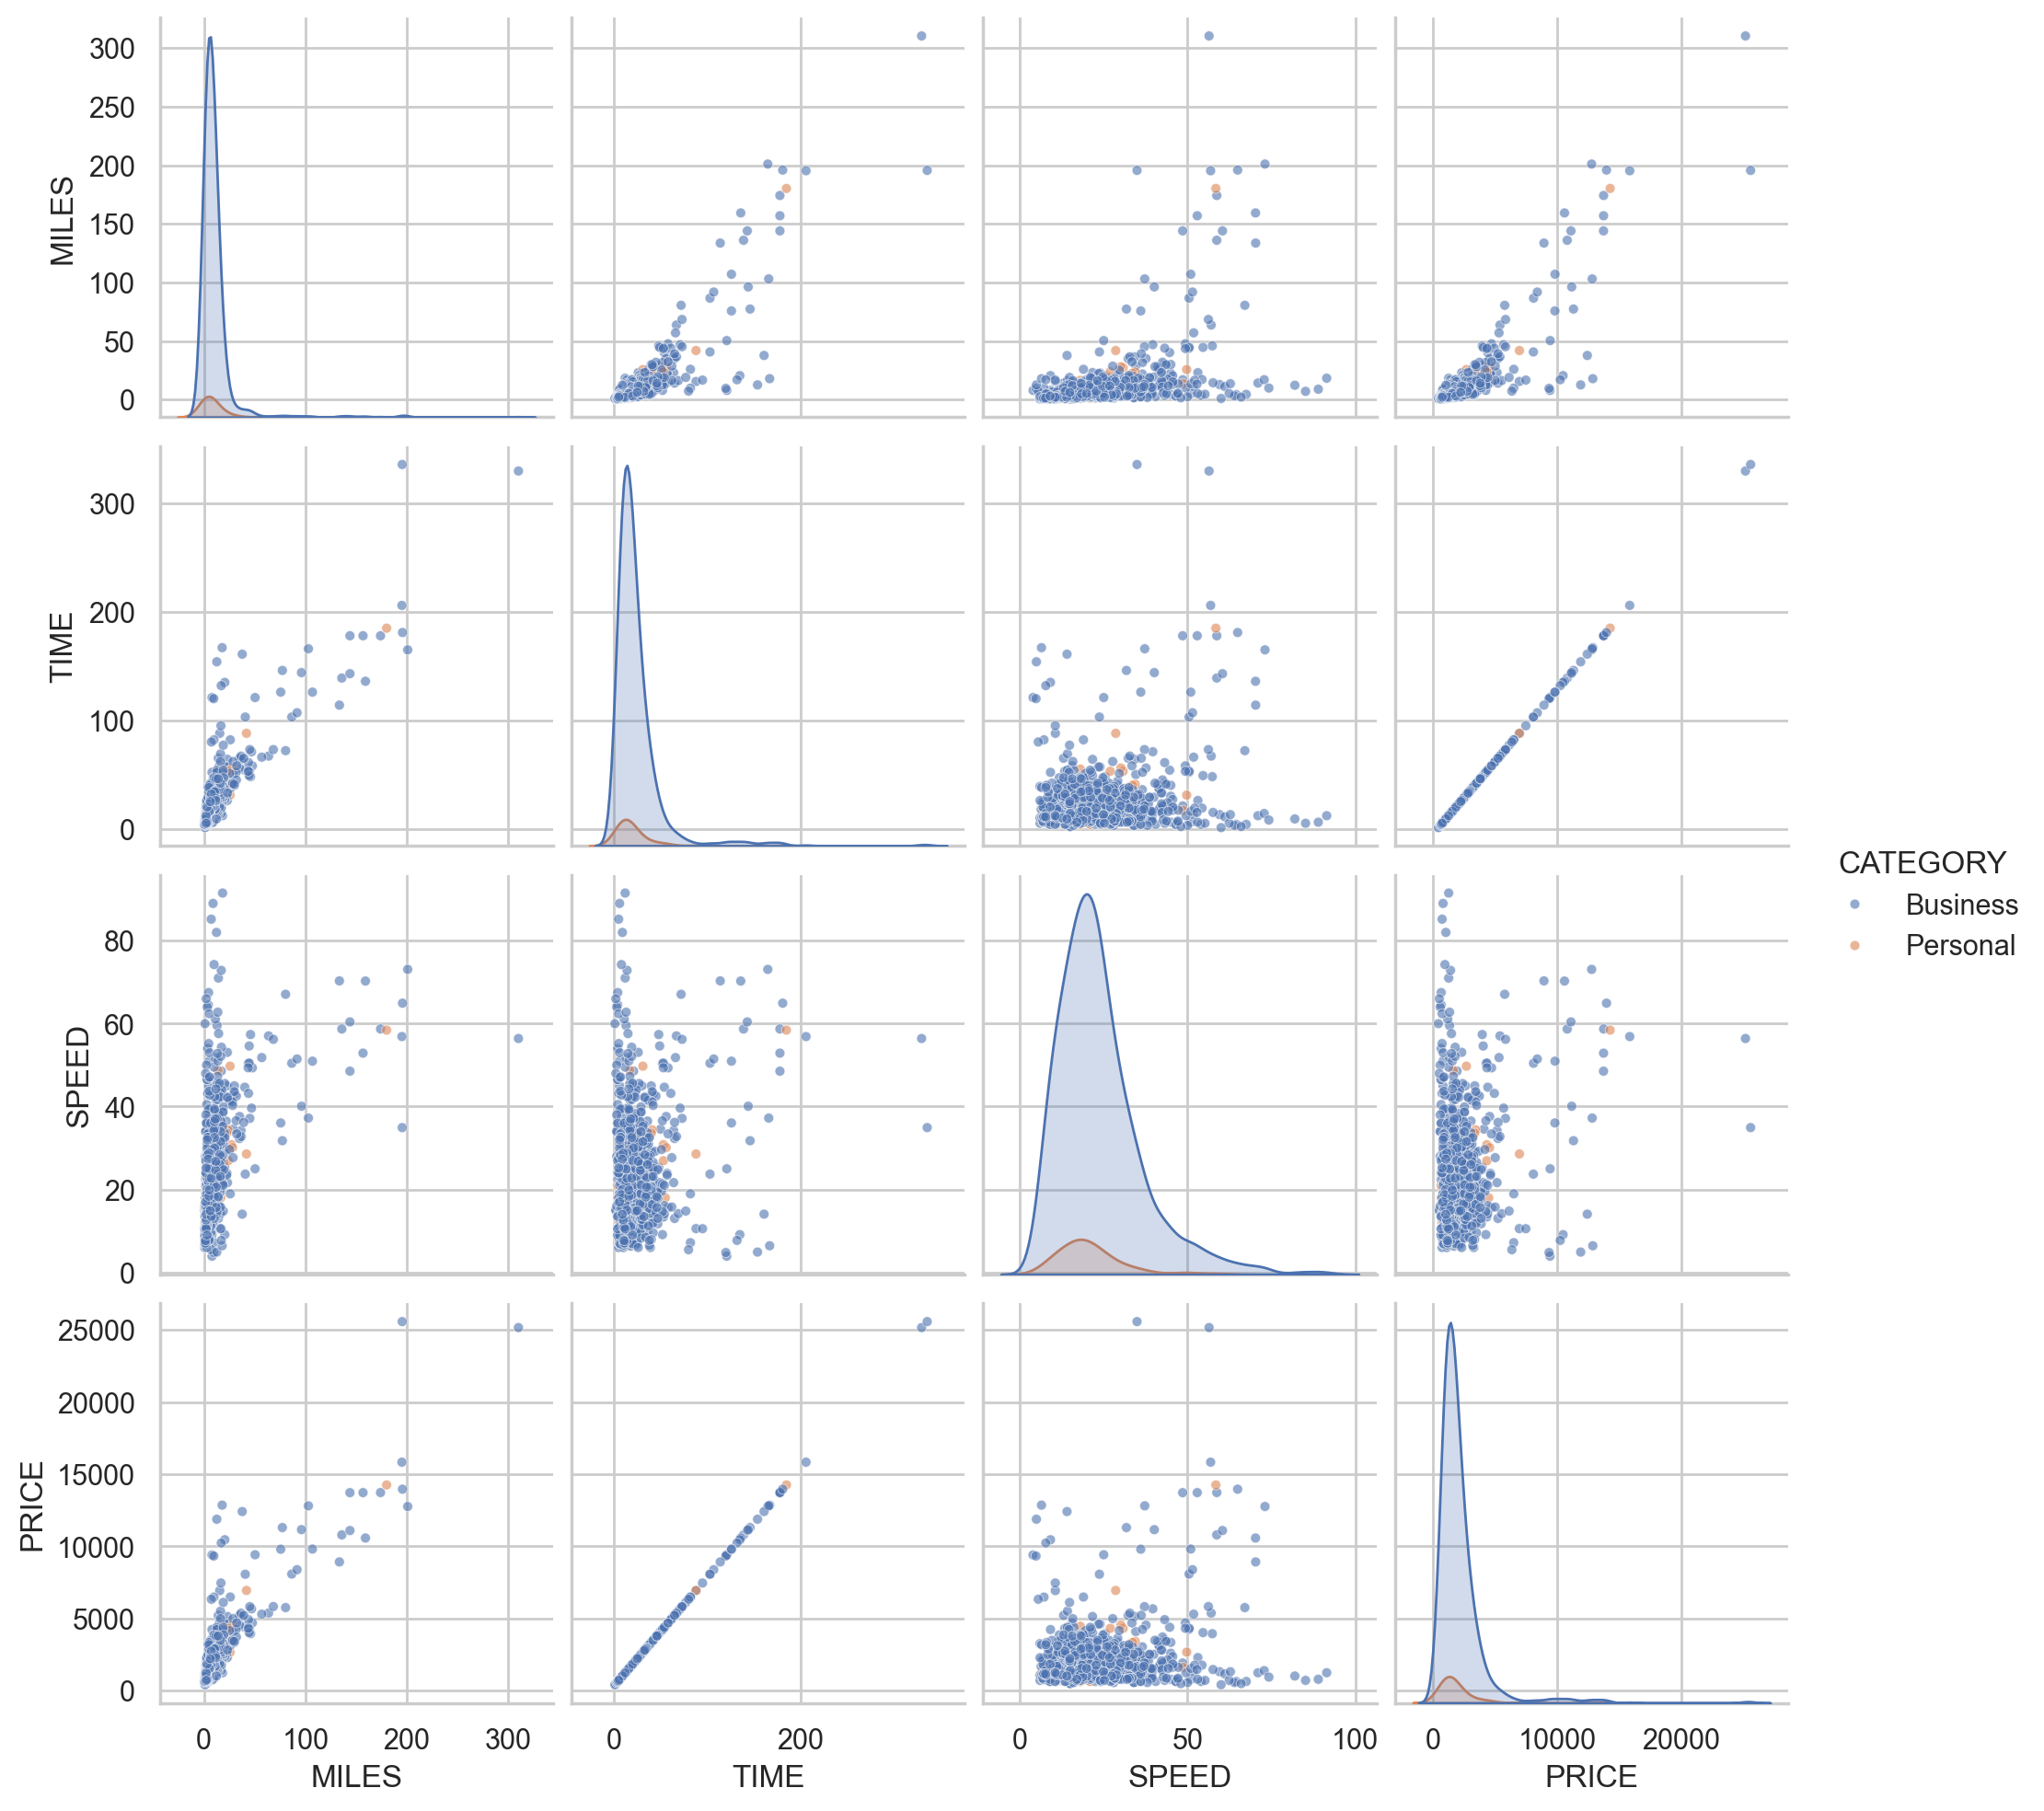

In [6]:
NUMERIC = ['MILES', 'TIME', 'SPEED', 'PRICE']
LABELS = {
    'MILES': 'Расстояние, мили',
    'TIME': 'Длительность, мин',
    'SPEED': 'Скорость, миль/ч',
    'PRICE': 'Стоимость',
}

sns.pairplot(trips, vars=NUMERIC, hue='CATEGORY', plot_kws={'s': 15, 'alpha': 0.6})
plt.show()

- `TIME` и `PRICE` лежат на одной прямой: стоимость полностью определяется длительностью.
- `MILES` связан с `TIME` и `PRICE` прямой зависимостью: чем дальше поездка, тем она дольше и дороже. Разброс растёт с расстоянием — одно и то же расстояние можно проехать за разное время.
- `SPEED` слабо связан с `TIME` и `PRICE`. У поездок до 5 миль скорость разбросана от 6 до 68 миль/ч, а у поездок длиннее 50 миль она не опускается ниже 25 — это поездки по трассе.
- Точки личных поездок (`Personal`) лежат в той же области, что и деловые, отдельной группы они не образуют.

Большинство точек сжато в левом нижнем углу, поэтому зависимость расстояния и длительности по целям поездки строю в логарифмическом масштабе. Поездки без цели на этом графике не показаны: их почти половина, и они закрывают остальные точки.

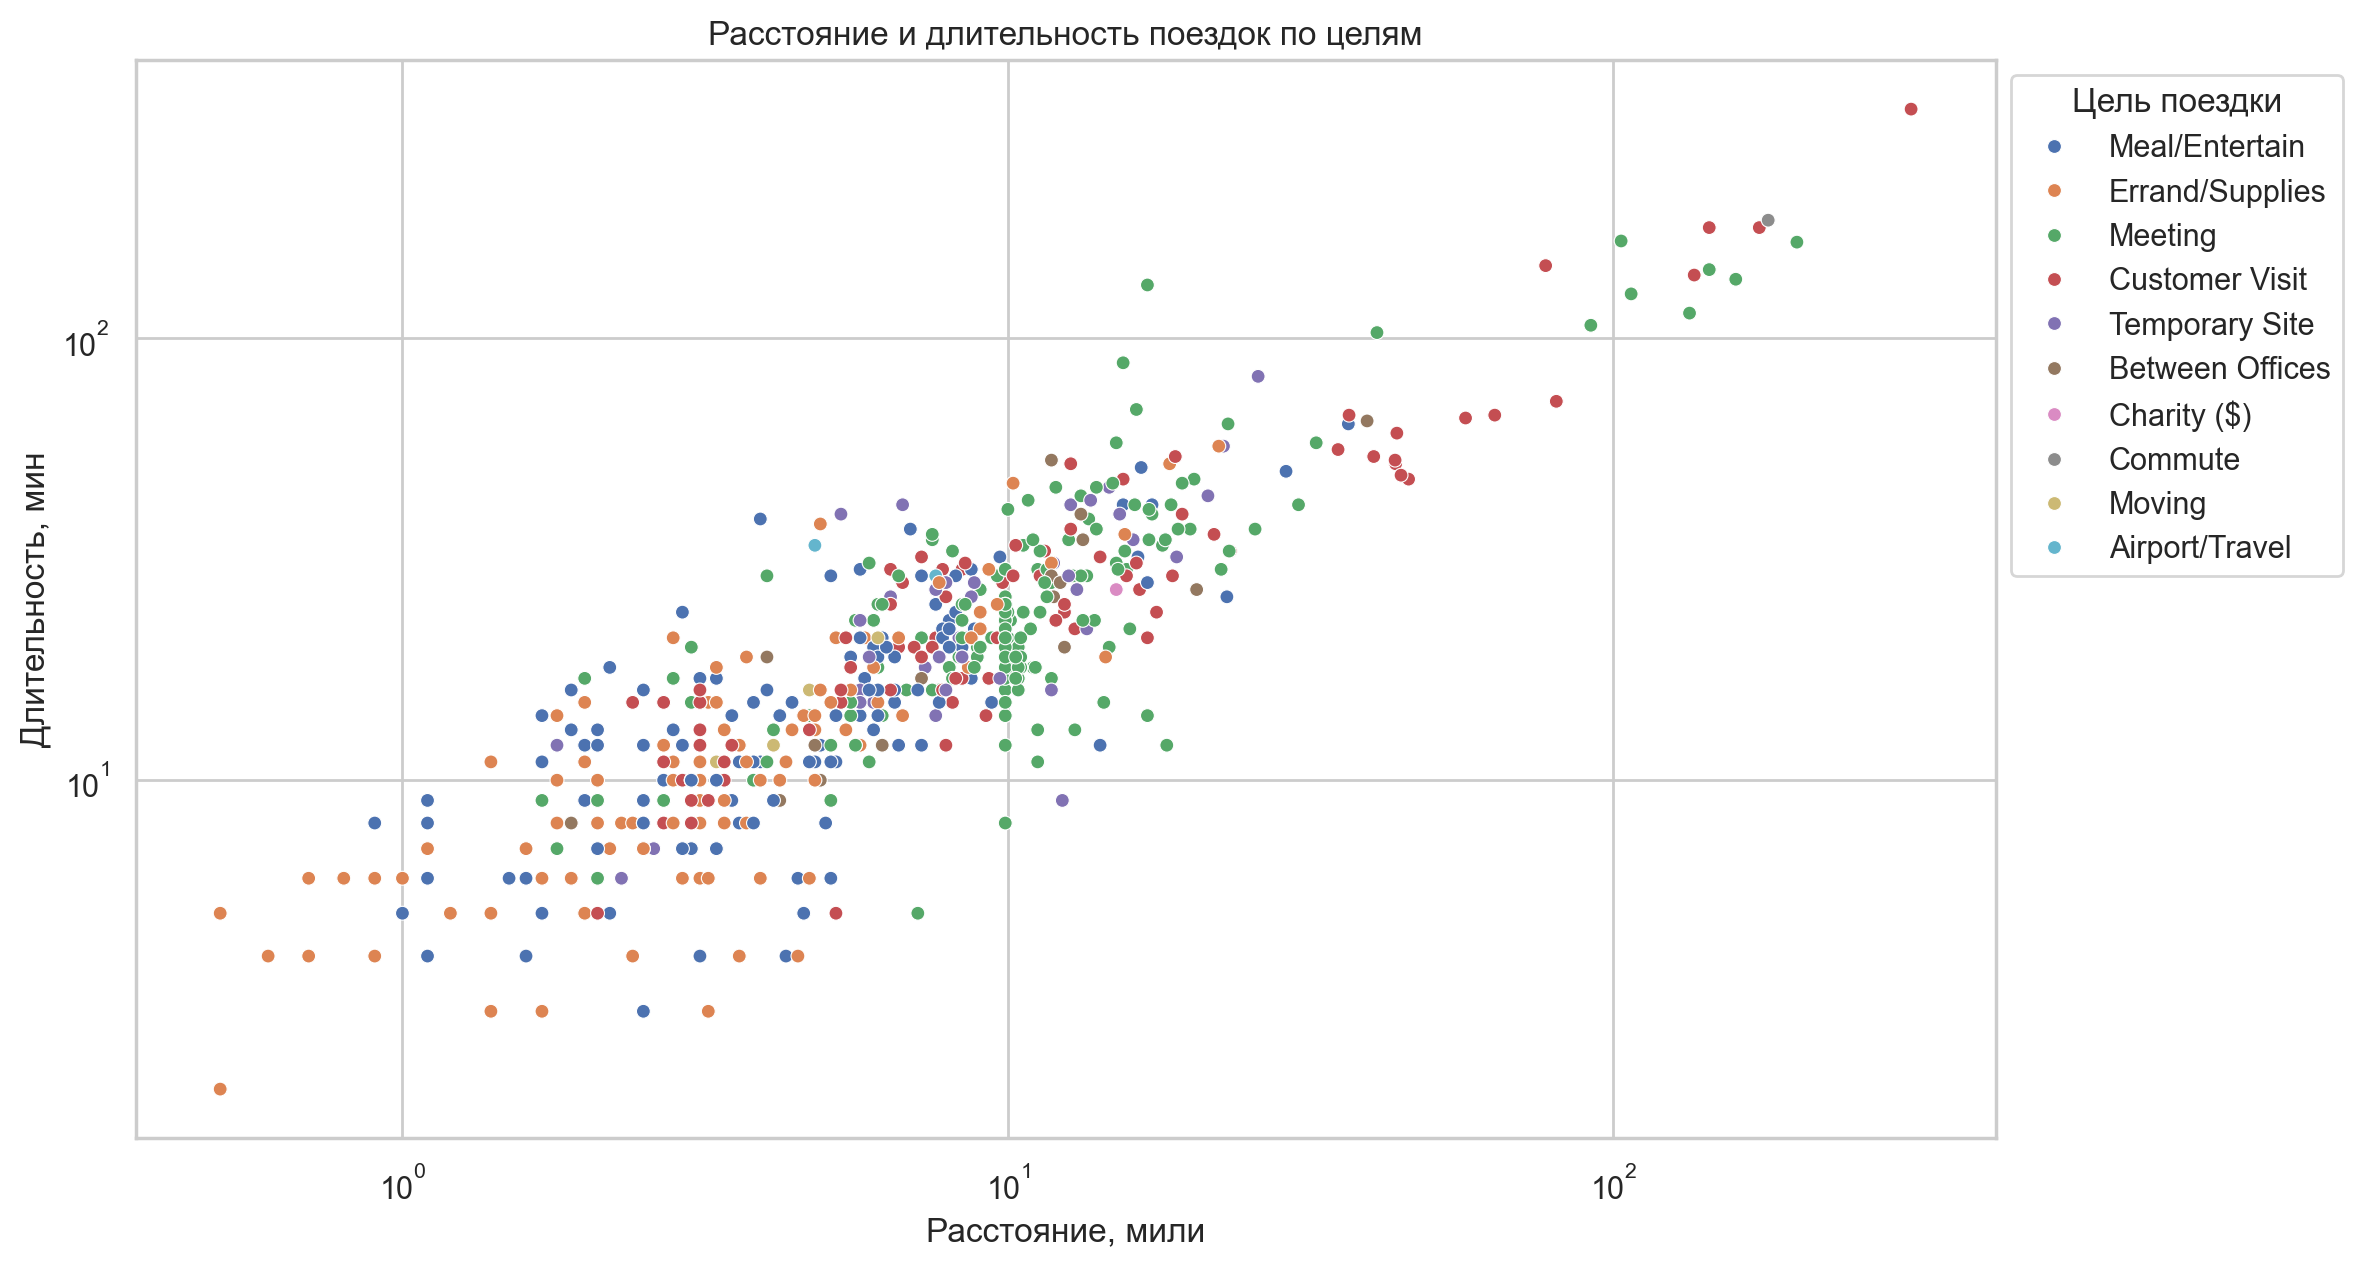

In [7]:
known_purpose = trips[trips['PURPOSE'] != 'не определена']

fig, ax = plt.subplots(figsize=(12, 7))
sns.scatterplot(data=known_purpose, x='MILES', y='TIME', hue='PURPOSE', s=25, ax=ax)
ax.set(xscale='log', yscale='log', xlabel=LABELS['MILES'], ylabel=LABELS['TIME'],
       title='Расстояние и длительность поездок по целям')
ax.legend(title='Цель поездки', bbox_to_anchor=(1, 1))
plt.show()

Точки вытянуты вдоль диагонали — длительность растёт вместе с расстоянием. Цели поездок занимают разные участки этой диагонали: Errand/Supplies и Meal/Entertain в основном до 10 миль, а в правой верхней части, дальше 30 миль, почти только Customer Visit и Meeting.

## 4. Гистограммы

Количество bins подбираю по правилу Фридмана — Диакониса: ширина интервала равна $2 \cdot IQR / \sqrt[3]{n}$. Правило опирается на межквартильный размах, поэтому на ширину интервала не влияют выбросы. В NumPy оно вызывается как `bins='fd'`.

В верхнем ряду гистограммы в обычной шкале, в нижнем — в логарифмической. Для нижнего ряда правило применено к логарифмам значений, а границы интервалов переведены обратно возведением 10 в степень: так интервалы получаются одинаковыми в логарифмической шкале.

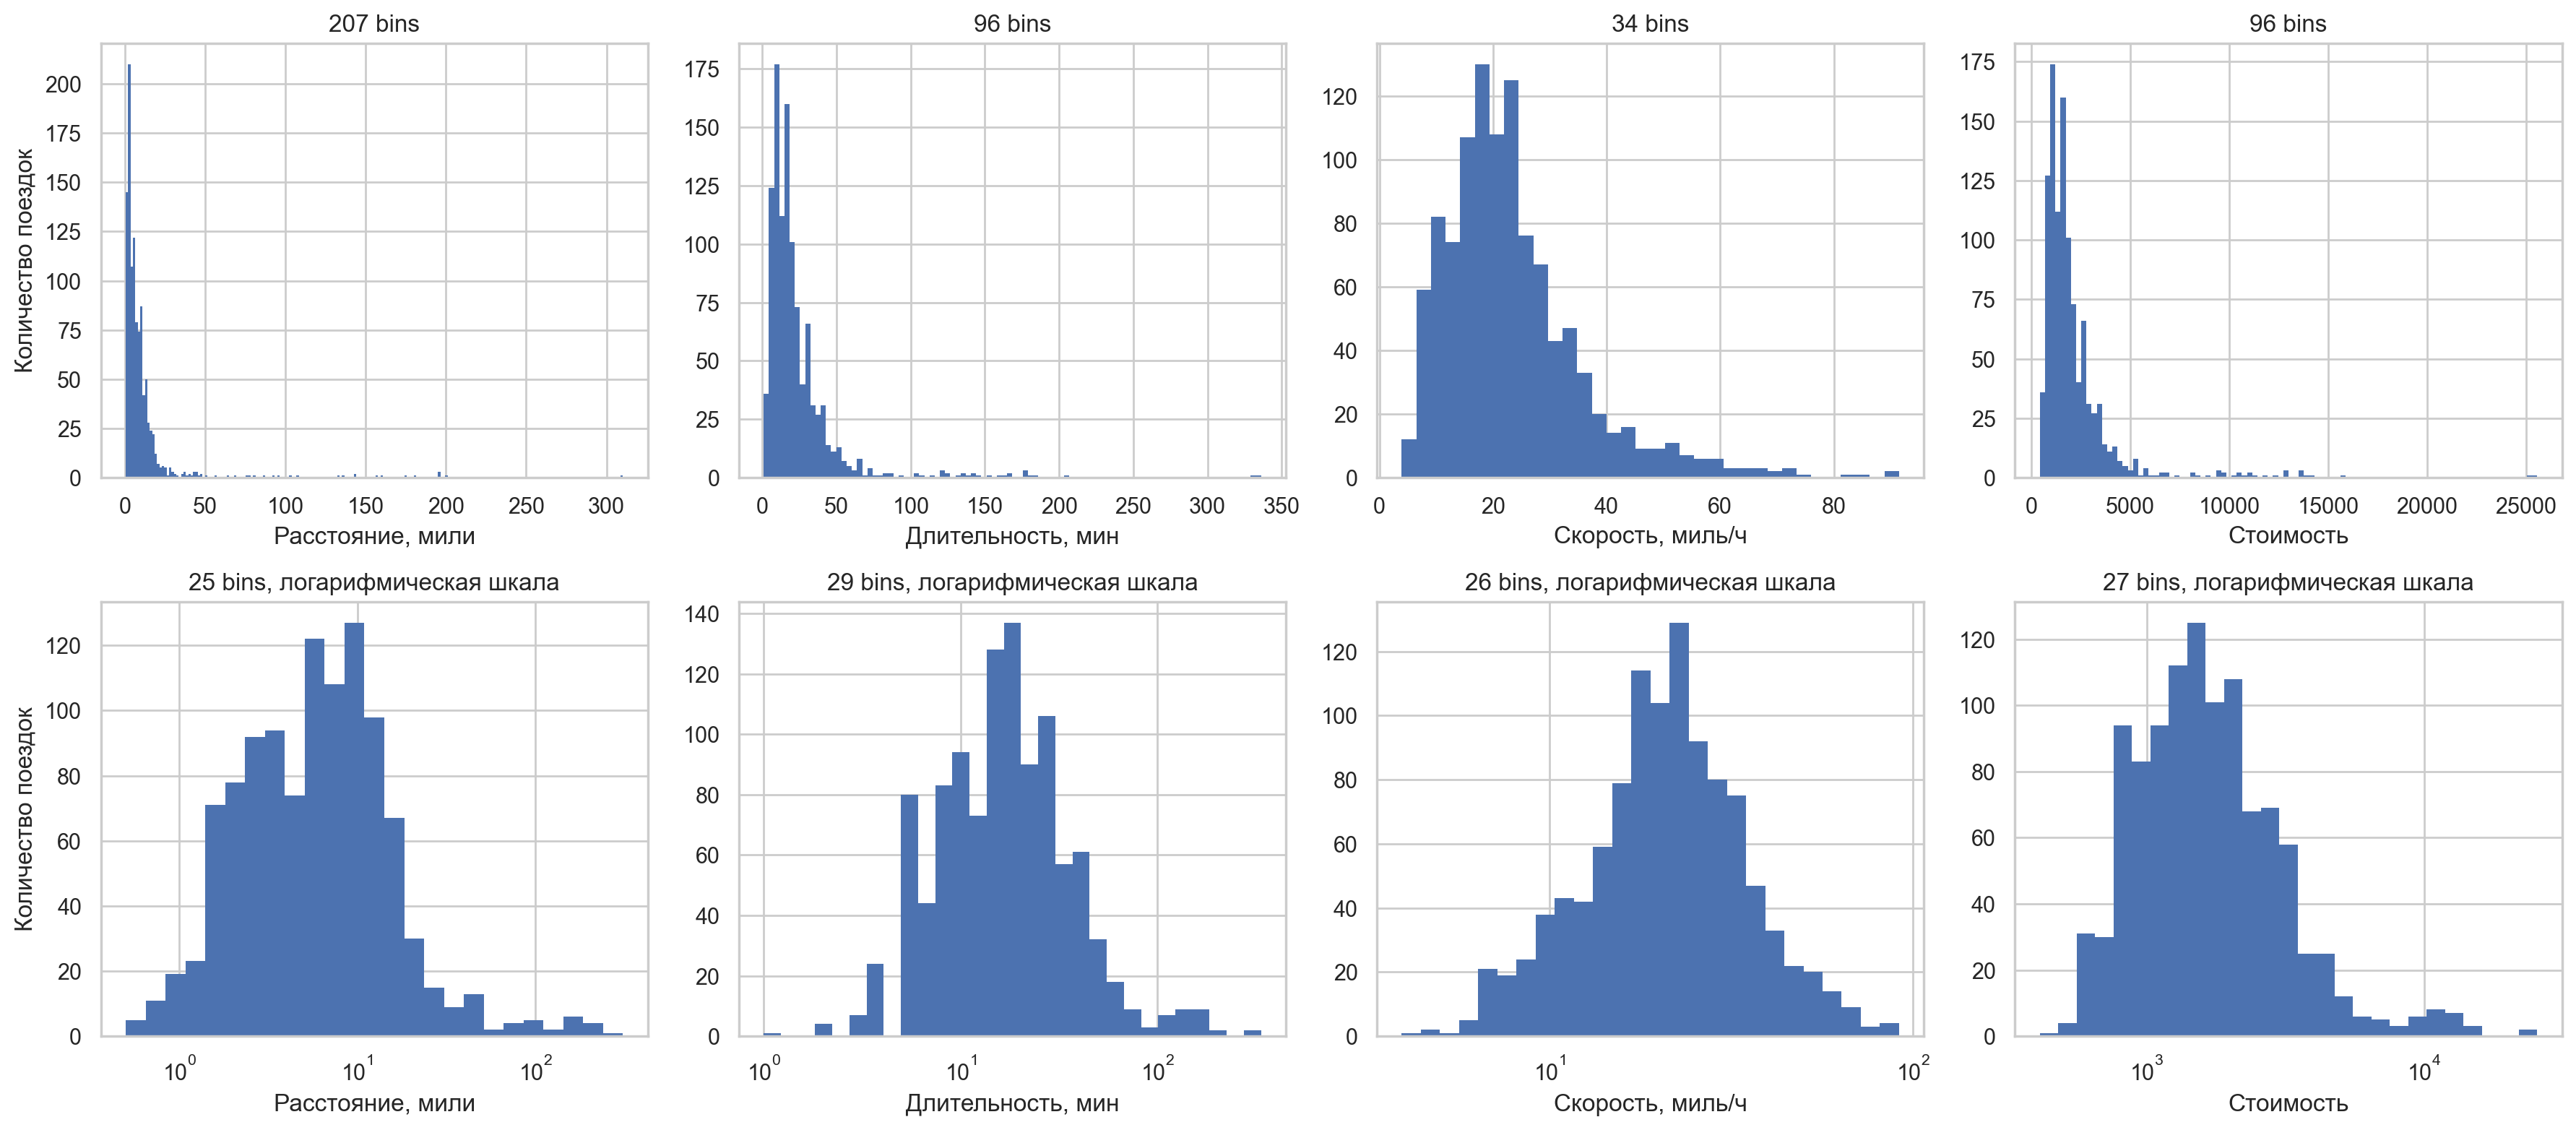

In [8]:
fig, axes = plt.subplots(2, len(NUMERIC), figsize=(18, 8))

for i, column in enumerate(NUMERIC):
    values = trips[column]

    bins = np.histogram_bin_edges(values, bins='fd')
    axes[0, i].hist(values, bins=bins, linewidth=0)
    axes[0, i].set(title=f'{len(bins) - 1} bins', xlabel=LABELS[column])

    log_bins = 10 ** np.histogram_bin_edges(np.log10(values),
                                            bins='fd')
    axes[1, i].hist(values, bins=log_bins, linewidth=0)
    axes[1, i].set(title=f'{len(log_bins) - 1} bins, логарифмическая шкала',
                   xlabel=LABELS[column], xscale='log')

axes[0, 0].set_ylabel('Количество поездок')
axes[1, 0].set_ylabel('Количество поездок')

fig.tight_layout()
plt.show()

В обычной шкале у `MILES`, `TIME` и `PRICE` правило даёт 96–207 bins, но почти все поездки попадают в первые интервалы, а справа тянется длинный редкий хвост: 25 поездок длиннее 50 миль при медиане 6. Такие гистограммы показывают только асимметрию, форму основной массы на них не разглядеть. У `SPEED` хвост короче, и 34 bins хватает: распределение одновершинное, пик около 20 миль/ч, правая сторона длиннее левой.

В логарифмической шкале всем признакам хватает 25–29 bins, длинный хвост сжимается, и распределения становятся почти симметричными. У `MILES` два пика — около 3 миль и в диапазоне 5–10 миль, между ними провал около 4 миль. У `TIME` слева видны пустые интервалы: длительность записана целыми минутами, и между 1, 2 и 3 минутами значений нет.

Для этих данных подходит логарифмическая шкала с 25–29 bins.

### Другие способы выбора количества bins

Кроме правила Фридмана — Диакониса, сравниваю ещё пять способов, все они есть в `np.histogram_bin_edges`. Здесь $n$ — число поездок, $k$ — количество bins, $h$ — ширина интервала.

| Способ | Формула | В NumPy |
|---|---|---|
| Стёрджес | $k = \lceil \log_2 n \rceil + 1$ | `'sturges'` |
| Квадратный корень | $k = \lceil \sqrt{n} \rceil$ | `'sqrt'` |
| Райс | $k = \lceil 2 \sqrt[3]{n} \rceil$ | `'rice'` |
| Скотт | $h = 3.49 \cdot \sigma / \sqrt[3]{n}$ | `'scott'` |
| Доан | $k = 1 + \log_2 n + \log_2 (1 + \lvert g_1 \rvert / \sigma_{g_1})$ | `'doane'` |

Первые три формулы зависят только от $n$. Правило Скотта опирается на стандартное отклонение $\sigma$ и выведено для нормального распределения. Правило Доана — это правило Стёрджеса с поправкой на асимметрию: $g_1$ — коэффициент асимметрии, $\sigma_{g_1}$ — его стандартная ошибка.

Сначала считаю, сколько bins даёт каждый способ в обычной и в логарифмической шкале:

In [9]:
BIN_RULES = {
    'sturges': 'Стёрджес',
    'sqrt': 'Квадратный корень',
    'rice': 'Райс',
    'scott': 'Скотт',
    'doane': 'Доан',
    'fd': 'Фридман — Диаконис',
}


def bin_edges(values, rule, log_scale):
    if log_scale:
        return 10 ** np.histogram_bin_edges(np.log10(values), bins=rule)
    return np.histogram_bin_edges(values, bins=rule)


scales = {False: 'обычная', True: 'логарифмическая'}
bin_counts = pd.DataFrame(
    {
        name: [len(bin_edges(trips[column], rule, log_scale)) - 1
               for log_scale in scales for column in NUMERIC]
        for rule, name in BIN_RULES.items()
    },
    index=pd.MultiIndex.from_product([scales.values(), NUMERIC],
                                     names=['Шкала', 'Признак']),
)
bin_counts

Стёрджес  Квадратный корень  Райс  Скотт  Доан  \
Шкала           Признак                                                   
обычная         MILES          12                 33    21     42    18   
                TIME           12                 33    21     36    18   
                SPEED          12                 33    21     21    16   
                PRICE          12                 33    21     36    18   
логарифмическая MILES          12                 33    21     20    14   
                TIME           12                 33    21     23    14   
                SPEED          12                 33    21     19    13   
                PRICE          12                 33    21     20    15   

                         Фридман — Диаконис  
Шкала           Признак                      
обычная         MILES                   207  
                TIME                     96  
                SPEED                    34  
                PRICE                    96  
логарифмическая MILES                    25  
                TIME                     29  
                SPEED                    26  
                PRICE                    27

Стёрджес, квадратный корень и Райс дают одно и то же количество bins для всех признаков и в обеих шкалах: 12, 33 и 21. Эти формулы зависят только от числа поездок, форма распределения на них не влияет.

Скотт и Доан учитывают данные, но тоже дают немного: 16–42 bins в обычной шкале и 13–23 в логарифмической. Фридман — Диаконис в обычной шкале выделяется: у `MILES`, `TIME` и `PRICE` он даёт 96–207 bins. IQR не чувствителен к хвосту, поэтому ширина интервала подбирается по плотной середине распределения, и такими узкими интервалами приходится покрывать весь размах, у расстояния — до 310 миль. У Скотта всё наоборот: хвост увеличивает стандартное отклонение, и интервалы получаются шире. Для расстояния ширина интервала по Скотту — 7.4 мили, по Фридману — Диаконису — 1.5 мили.

Гистограммы в обычной шкале:

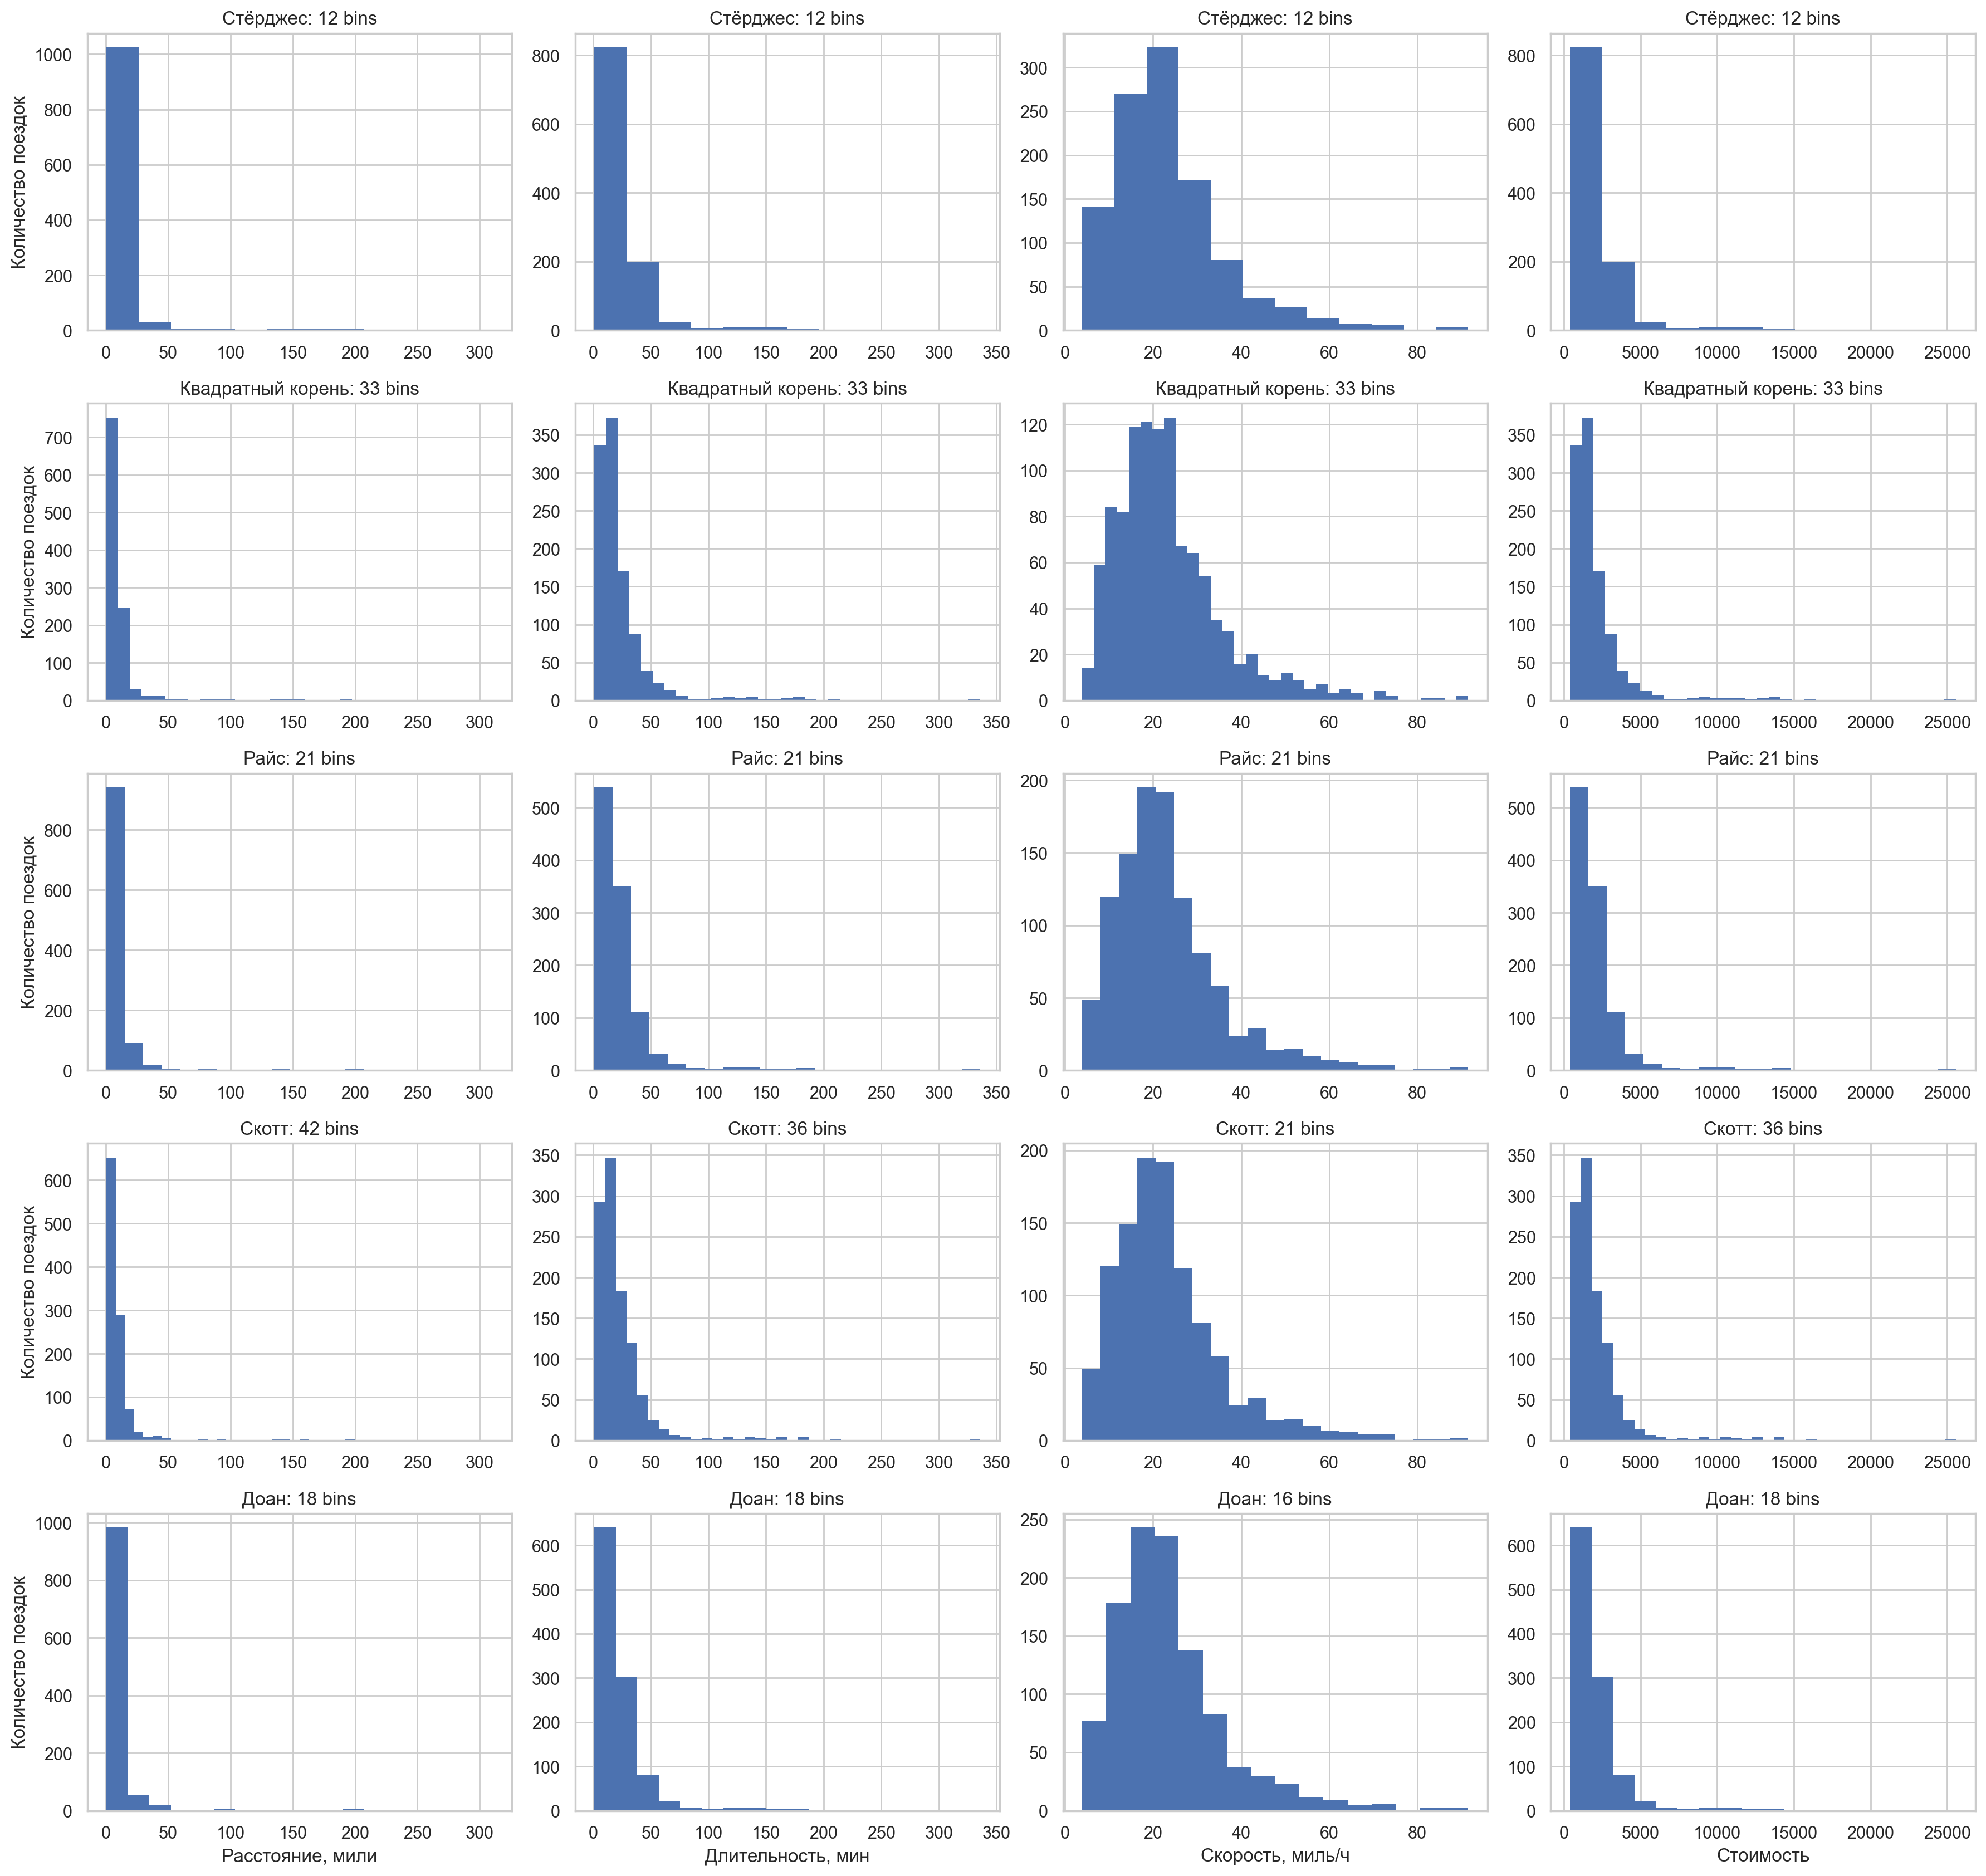

In [10]:
def plot_histograms(log_scale):
    rules = [rule for rule in BIN_RULES if rule != 'fd']
    fig, axes = plt.subplots(len(rules), len(NUMERIC), figsize=(18, 17))

    for row, rule in zip(axes, rules):
        for ax, column in zip(row, NUMERIC):
            bins = bin_edges(trips[column], rule, log_scale)
            ax.hist(trips[column], bins=bins, linewidth=0)
            ax.set(title=f'{BIN_RULES[rule]}: {len(bins) - 1} bins',
                   xscale='log' if log_scale else 'linear')
        row[0].set_ylabel('Количество поездок')

    for ax, column in zip(axes[-1], NUMERIC):
        ax.set_xlabel(LABELS[column])

    fig.tight_layout()
    plt.show()


plot_histograms(log_scale=False)

Для `MILES`, `TIME` и `PRICE` все пять способов дают слишком широкие интервалы. По Стёрджесу интервал расстояния шириной 26 миль, в первый попадает 1025 поездок из 1080, и гистограмма по сути состоит из одного столбца. У Доана и Райса картина почти та же. Квадратный корень и Скотт дают интервалы по 9 и 7 миль: видно, что больше всего поездок короче 10 миль, но форму основной массы всё равно не разглядеть. Справа при любом способе тянутся пустые и почти пустые интервалы хвоста.

У `SPEED` хвост короткий, и здесь подходит любой способ. По Райсу и Скотту получается одинаково, 21 bin шириной 4.2 мили/ч: хорошо видны пик около 20 миль/ч и длинная правая сторона. При 12 bins Стёрджеса та же форма выглядит грубее, а при 33 bins квадратного корня появляются случайные зубцы.

Те же способы в логарифмической шкале:

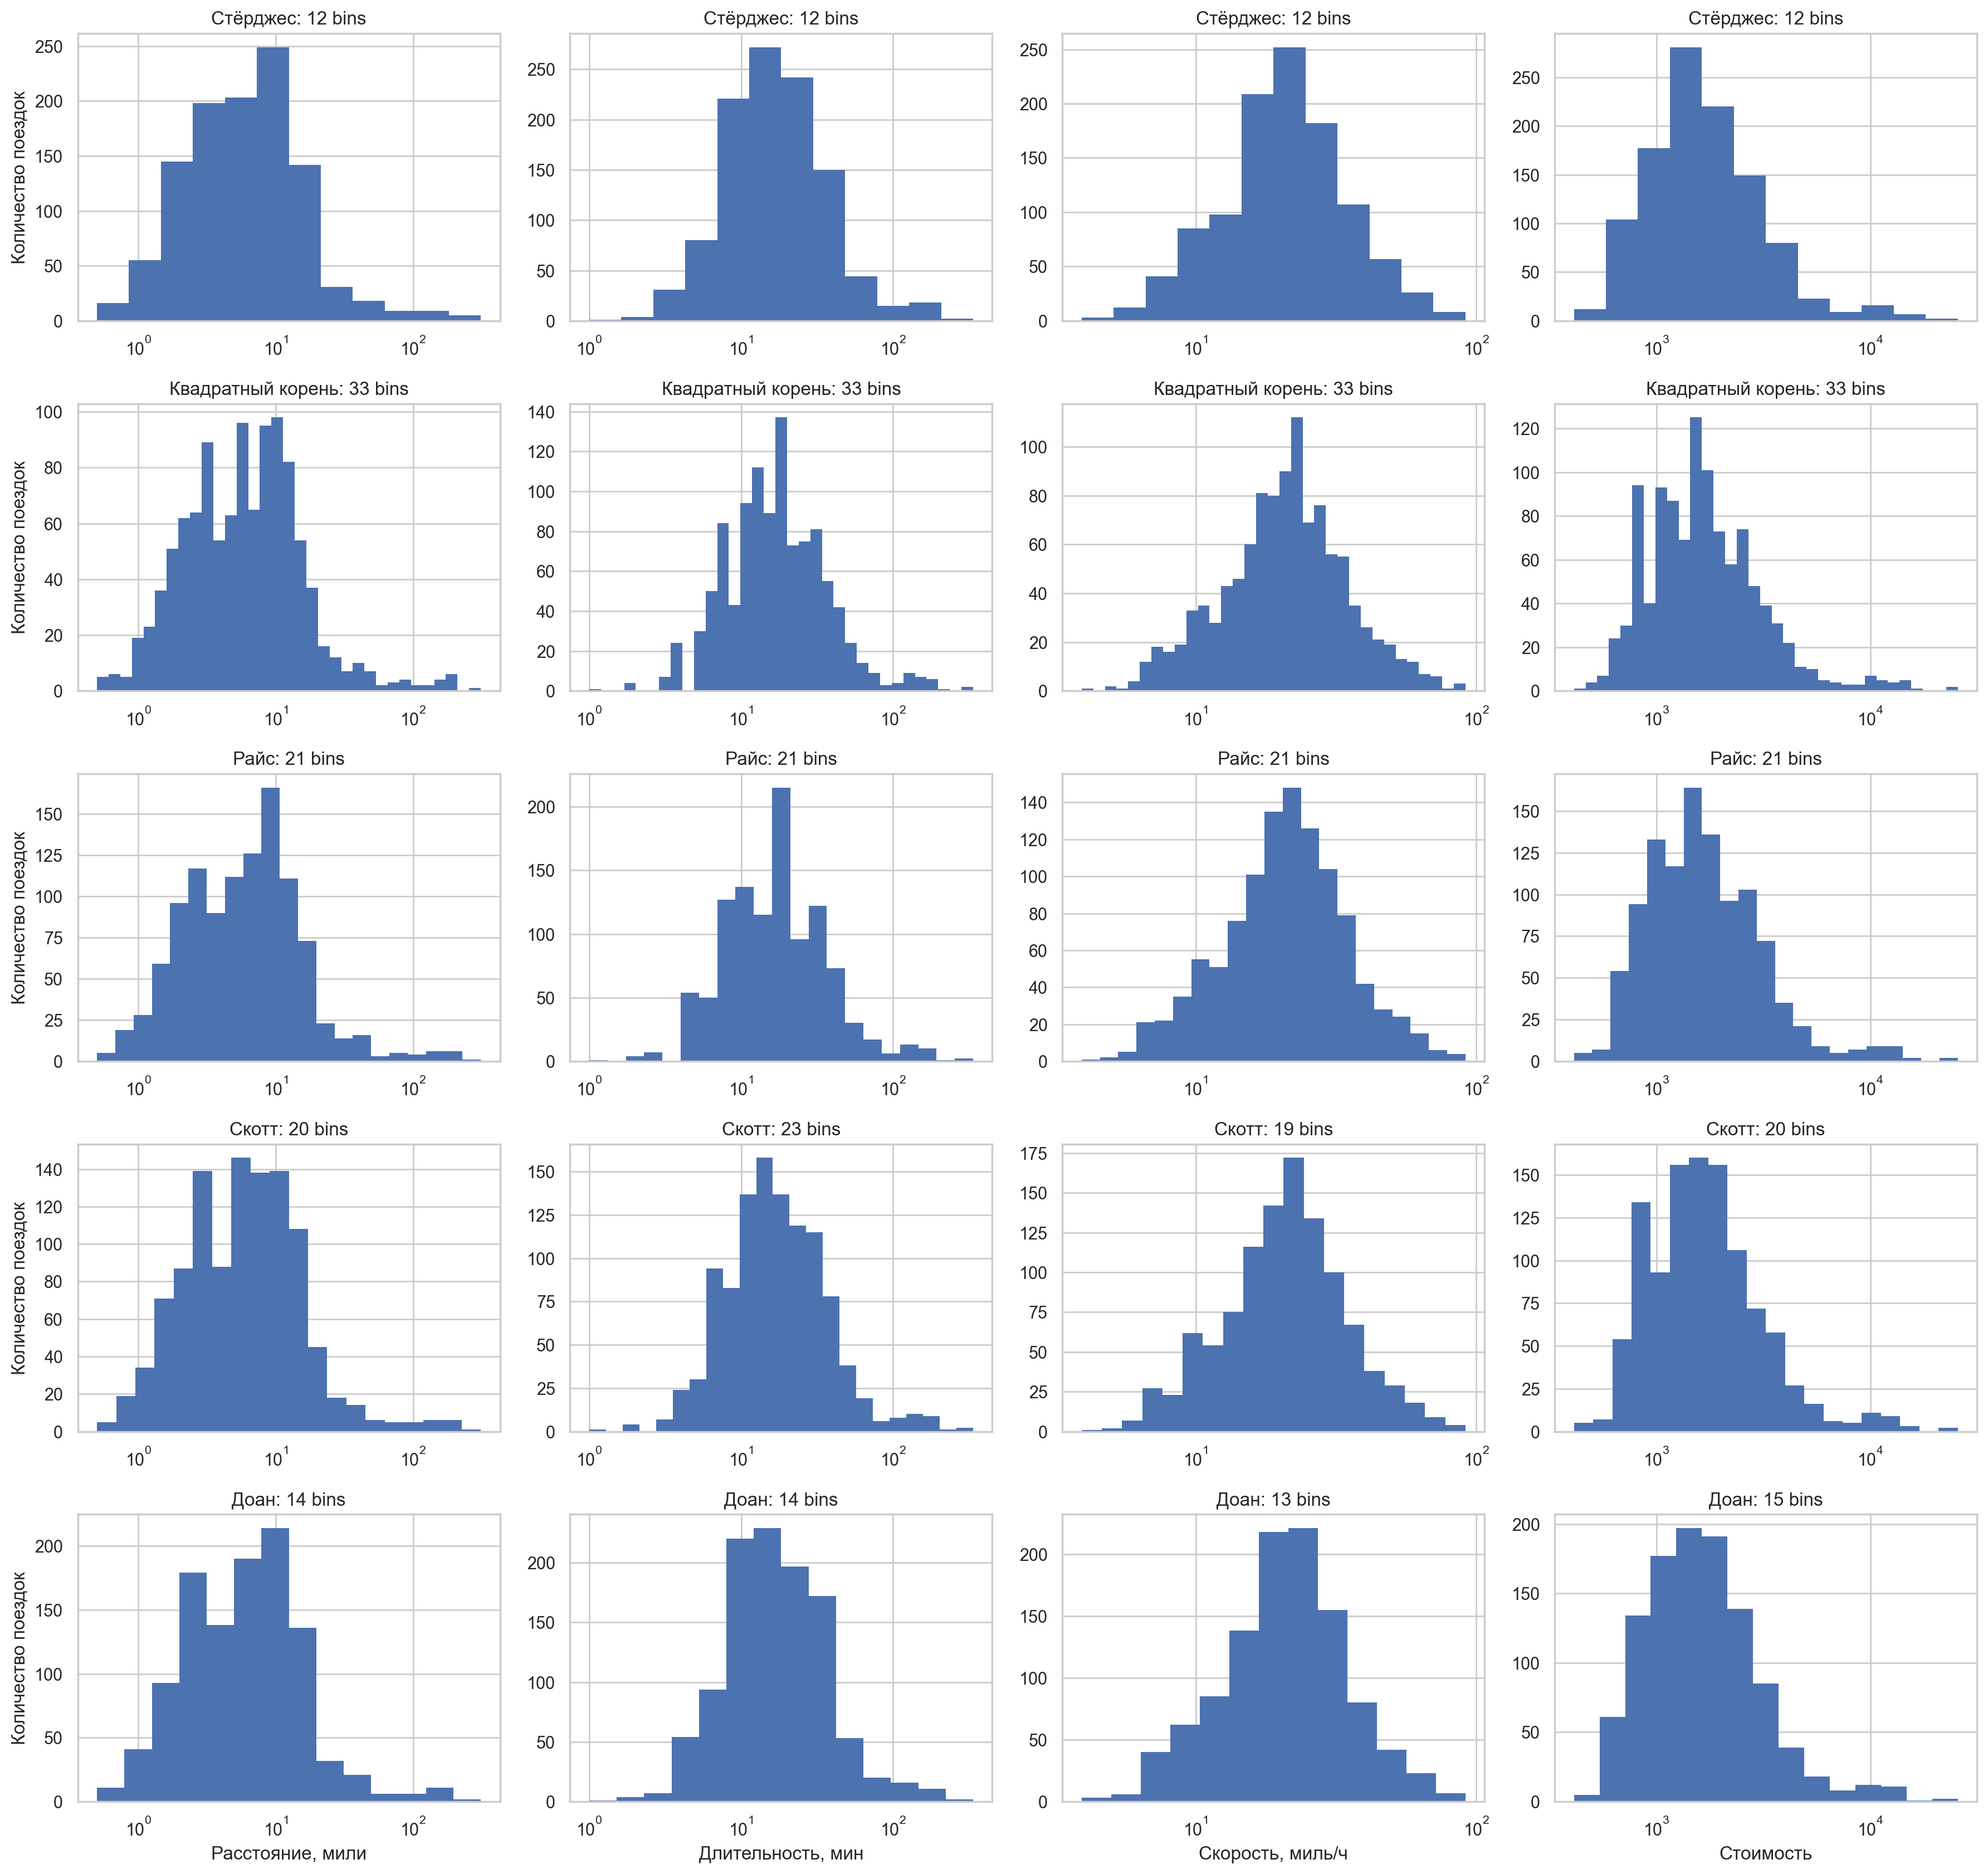

In [11]:
plot_histograms(log_scale=True)

В логарифмической шкале все способы дают почти симметричные распределения, как и правило Фридмана — Диакониса, различаются только детали.

- Стёрджес (12 bins) и Доан (13–15) — пустых интервалов нет, но интервалы крупные. У Стёрджеса на гистограмме `MILES` не видно провала около 4 миль между двумя пиками, который есть на остальных гистограммах.
- Квадратный корень (33 bins) — интервалы слишком узкие. У `TIME` 6 пустых интервалов и несколько отдельных высоких столбцов: длительность записана целыми минутами, и в узкий интервал попадает то одно значение, то два.
- Райс (21) и Скотт (19–23) занимают промежуточное положение. По форме они почти не отличаются от Фридмана — Диакониса (25–29 bins), но пустых интервалов у `TIME` у них меньше: 2 против 5.

Итог: для признаков с длинным хвостом в обычной шкале не помогает никакая формула, проблема в самой шкале. В логарифмической шкале подходят Райс, Скотт и Фридман — Диаконис. Для `MILES`, `SPEED` и `PRICE` я оставляю Фридмана — Диакониса: оно даёт больше всего деталей, а пустых интервалов у этих признаков не больше двух. Для `TIME` лучше Райс или Скотт: у Фридмана — Диакониса из-за целых минут 5 пустых интервалов, почти как у квадратного корня. Стёрджесу при 1080 поездках не хватает интервалов, а квадратному корню их слишком много.

## 5. Корреляция и ковариация

Ковариация показывает, меняются ли две величины в одну сторону. Её значение зависит от единиц измерения, поэтому сравнивать ковариации разных пар нельзя. Корреляция — это ковариация, делённая на произведение стандартных отклонений, она всегда лежит в пределах от −1 до 1.

In [12]:
trips[NUMERIC].cov().round(1)

,MILES,TIME,SPEED,PRICE
MILES,480.3,528.0,130.4,39701.1
TIME,528.0,776.3,82.5,58321.9
SPEED,130.4,82.5,155.9,6221.0
PRICE,39701.1,58321.9,6221.0,4381519.5


Все ковариации положительные: при росте одного признака остальные в среднем тоже растут. Величина ковариации определяется масштабом: у пар со стоимостью она измеряется десятками тысяч, потому что сама стоимость измеряется тысячами. О силе связи по этой таблице судить нельзя.

Коэффициент Пирсона оценивает линейную связь. Коэффициент Спирмена считается по рангам значений и показывает монотонную связь любой формы, он также меньше чувствителен к выбросам.

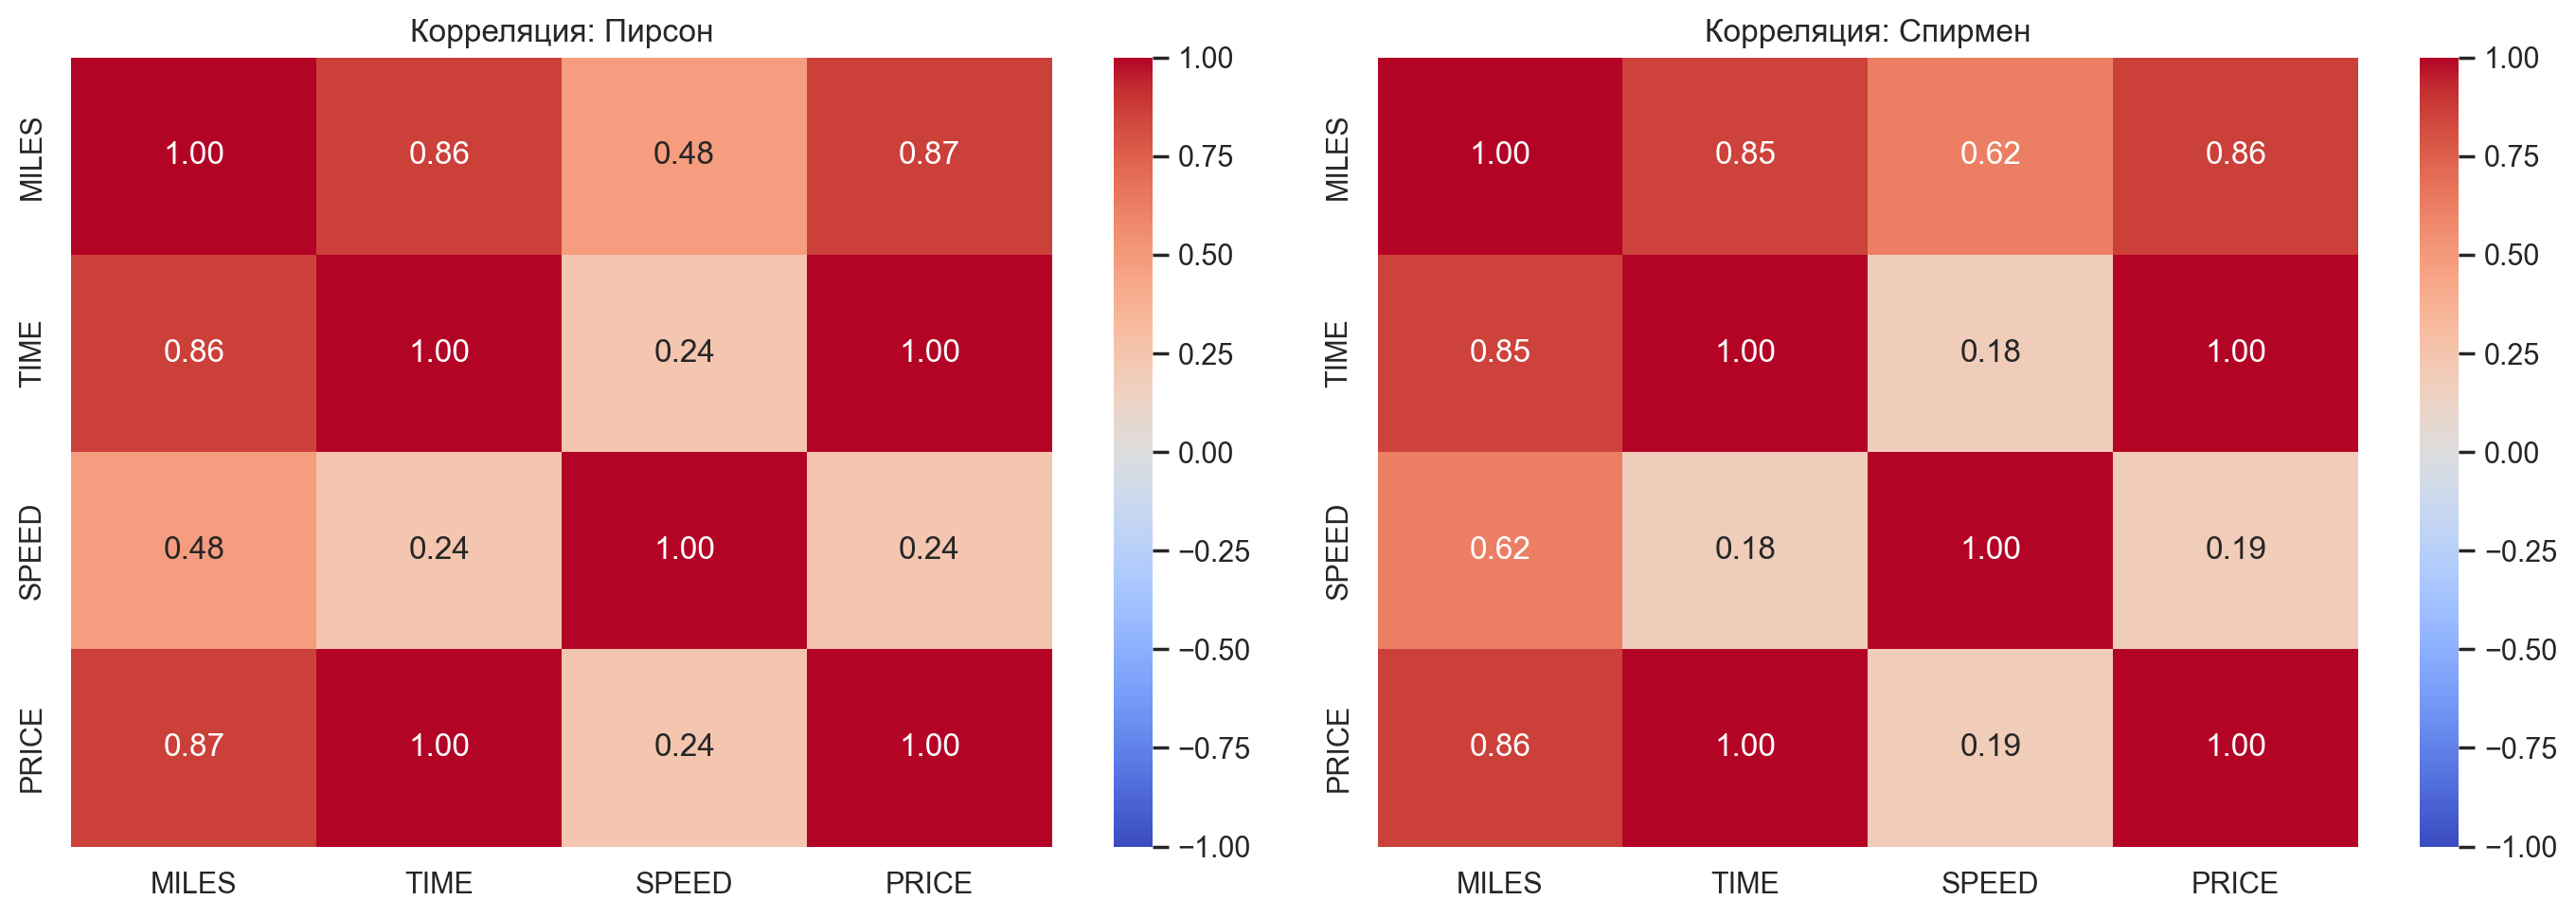

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(trips[NUMERIC].corr(method='pearson'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title('Корреляция: Пирсон')

sns.heatmap(trips[NUMERIC].corr(method='spearman'), annot=True, fmt='.2f',
            cmap='coolwarm', vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title('Корреляция: Спирмен')

fig.tight_layout()
plt.show()

- `TIME` и `PRICE` — корреляция 1.00, связь линейная и полная.
- `MILES` с `TIME` и `PRICE` — 0.85–0.87 по обоим методам, сильная линейная связь.
- `MILES` и `SPEED` — 0.48 по Пирсону и 0.62 по Спирмену. Связь средняя, и она скорее монотонная, чем линейная: скорость растёт с расстоянием, но всё медленнее.
- `SPEED` с `TIME` и `PRICE` — 0.18–0.24, связь слабая. Долгая поездка может быть и дальней, и медленной из-за пробок.

Отрицательных корреляций нет. Так как корреляция `TIME` и `PRICE` равна единице, проверяю, по какой формуле считается стоимость:

In [14]:
slope, intercept = np.polyfit(trips['TIME'], trips['PRICE'], deg=1)
residuals = trips['PRICE'] - (slope * trips['TIME'] + intercept)
print(f'price = {slope:.1f} * time + {intercept:.1f}')
print(f'Наибольшее отклонение от прямой: {residuals.abs().max():.0f}')

price = 75.1 * time + 335.3
Наибольшее отклонение от прямой: 29


Стоимость — это около 335 за посадку и 75 за минуту поездки, отклонение от формулы не больше 29. От расстояния стоимость напрямую не зависит, только через длительность. Поэтому `PRICE` не несёт новой информации по сравнению с `TIME`.

## 6. Задания варианта

### Задание 1

Seaborn. Группировка по `CATEGORY` и количество поездок каждой цели, в группировке остаются сочетания с количеством поездок больше 2.

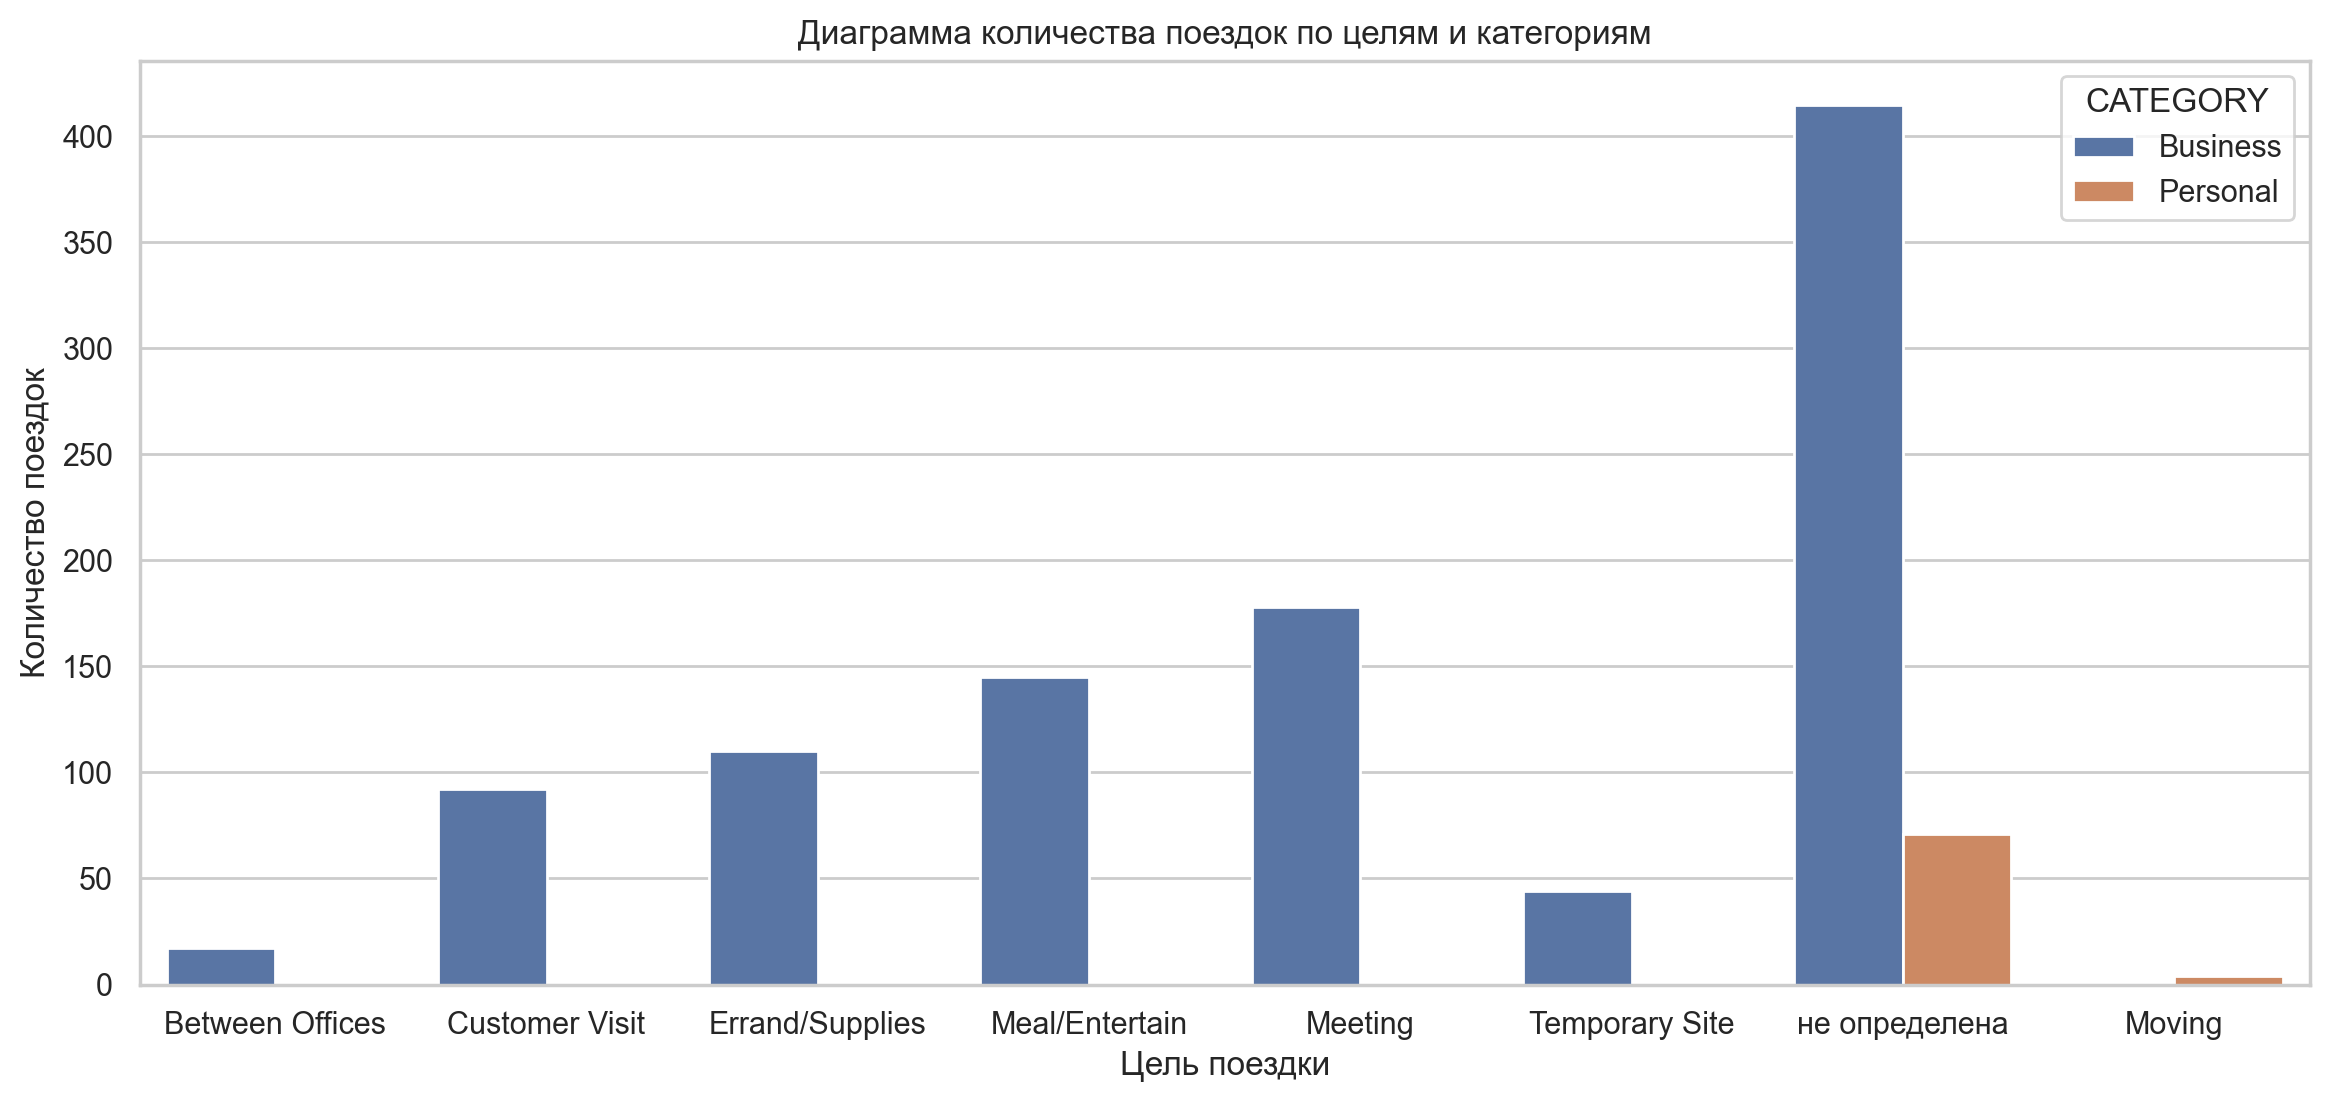

In [15]:
trip_counts = trips.groupby(['CATEGORY', 'PURPOSE']).size()
trip_counts = trip_counts.reset_index(name='count')
trip_counts = trip_counts[trip_counts['count'] > 2]

fig, ax = plt.subplots(figsize=(14, 6))
sns.barplot(data=trip_counts, x='PURPOSE', y='count',
            hue='CATEGORY', ax=ax)
ax.set(title='Диаграмма количества поездок по целям и категориям',
       xlabel='Цель поездки', ylabel='Количество поездок')
plt.show()

Фильтр убрал Airport/Travel (2 поездки), Charity ($) и Commute (по одной). Почти все поездки деловые: 1003 из 1080. Чаще всего у деловых поездок указаны цели Meeting (178), Meal/Entertain (145) и Errand/Supplies (110), но самый высокий столбец — «не определена» (415). У личных поездок цель почти никогда не указана: 71 из 77, из указанных после фильтра остался только Moving (4).

### Задание 2

Pandas. Сводная таблица — среднее количество миль по каждой цели поездки, только маркеры ★ зелёного цвета размером 18.

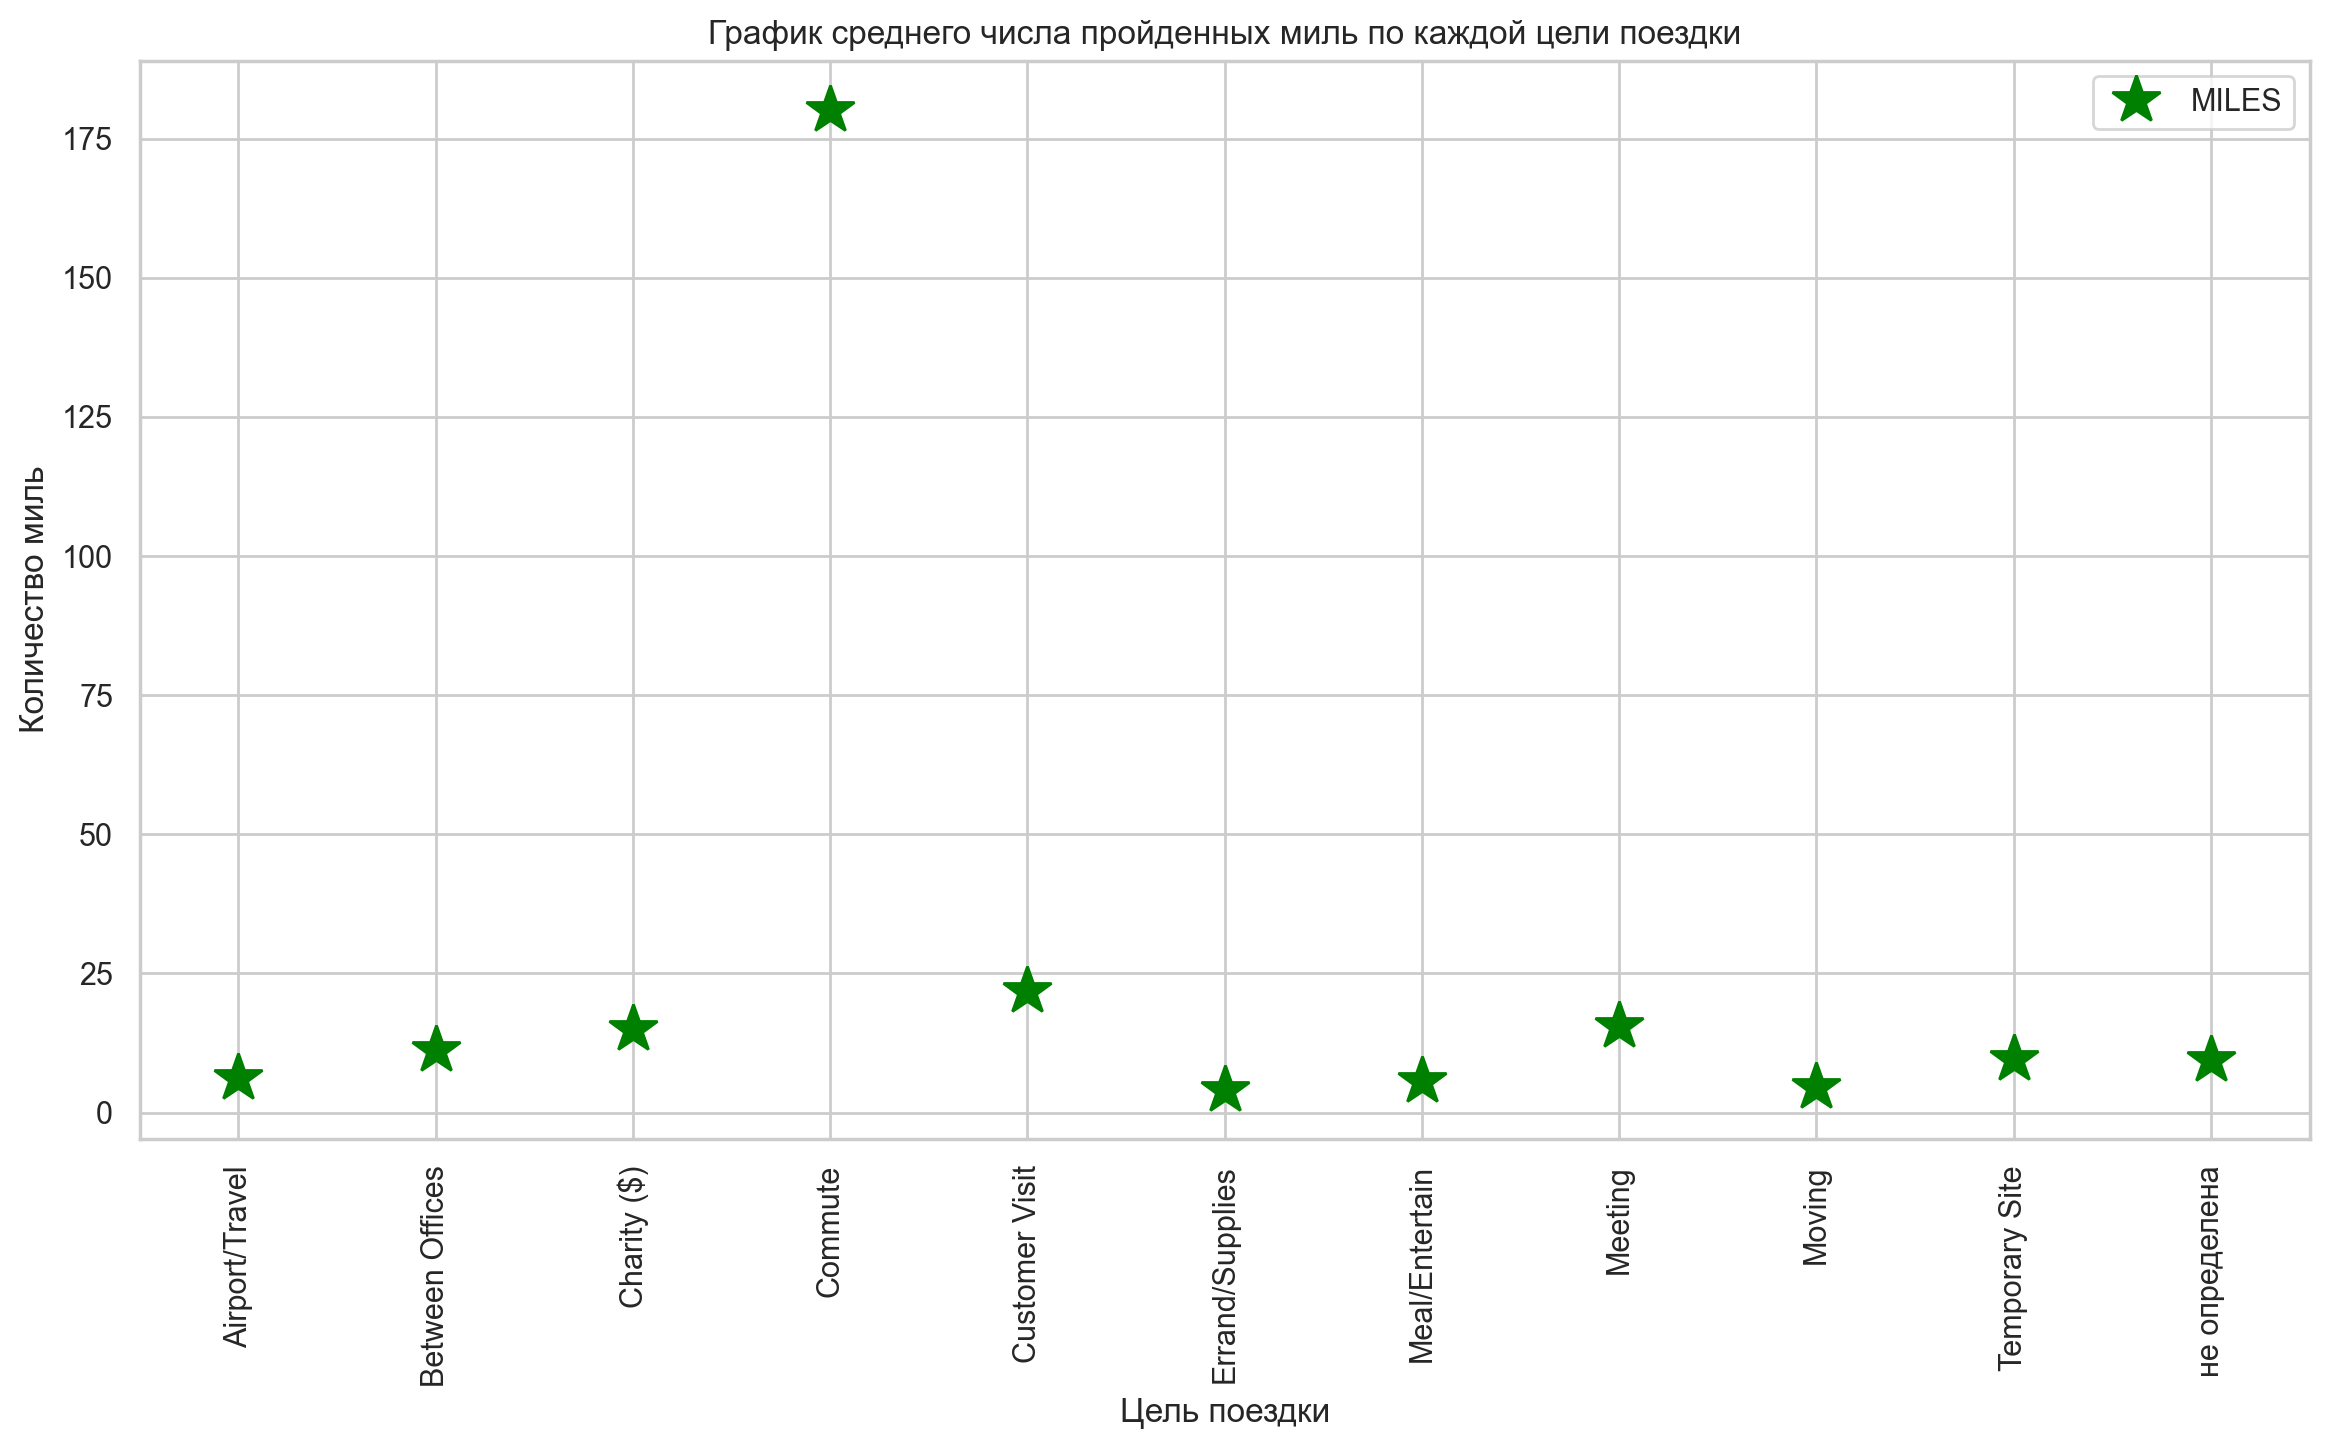

In [16]:
mean_miles = trips.pivot_table(index='PURPOSE', values='MILES',
                               aggfunc='mean')

ax = mean_miles.plot(style='*', color='green', markersize=18,
                     figsize=(14, 7), rot=90,
                     xticks=range(len(mean_miles)))
ax.set(title='График среднего числа пройденных миль по каждой цели поездки',
       xlabel='Цель поездки', ylabel='Количество миль')
plt.show()

Выше всех Commute — 180.2 мили, но это одна поездка, и о цели в целом она ничего не говорит. Остальные средние лежат в пределах 4–22 миль. Дальше всего в среднем ездят к клиентам (Customer Visit, 21.9) и на встречи (Meeting, 15.6), ближе всего — по поручениям (Errand/Supplies, 4.1), на переезд (Moving, 4.6) и на обед (Meal/Entertain, 5.7). Среднее чувствительно к дальним поездкам: у Customer Visit медиана всего 8.3 мили, это видно на диаграмме размаха в разделе 10.

### Задание 3

Matplotlib. Круговая диаграмма долей целей поездки, цели, у которых меньше 5 поездок, убраны.

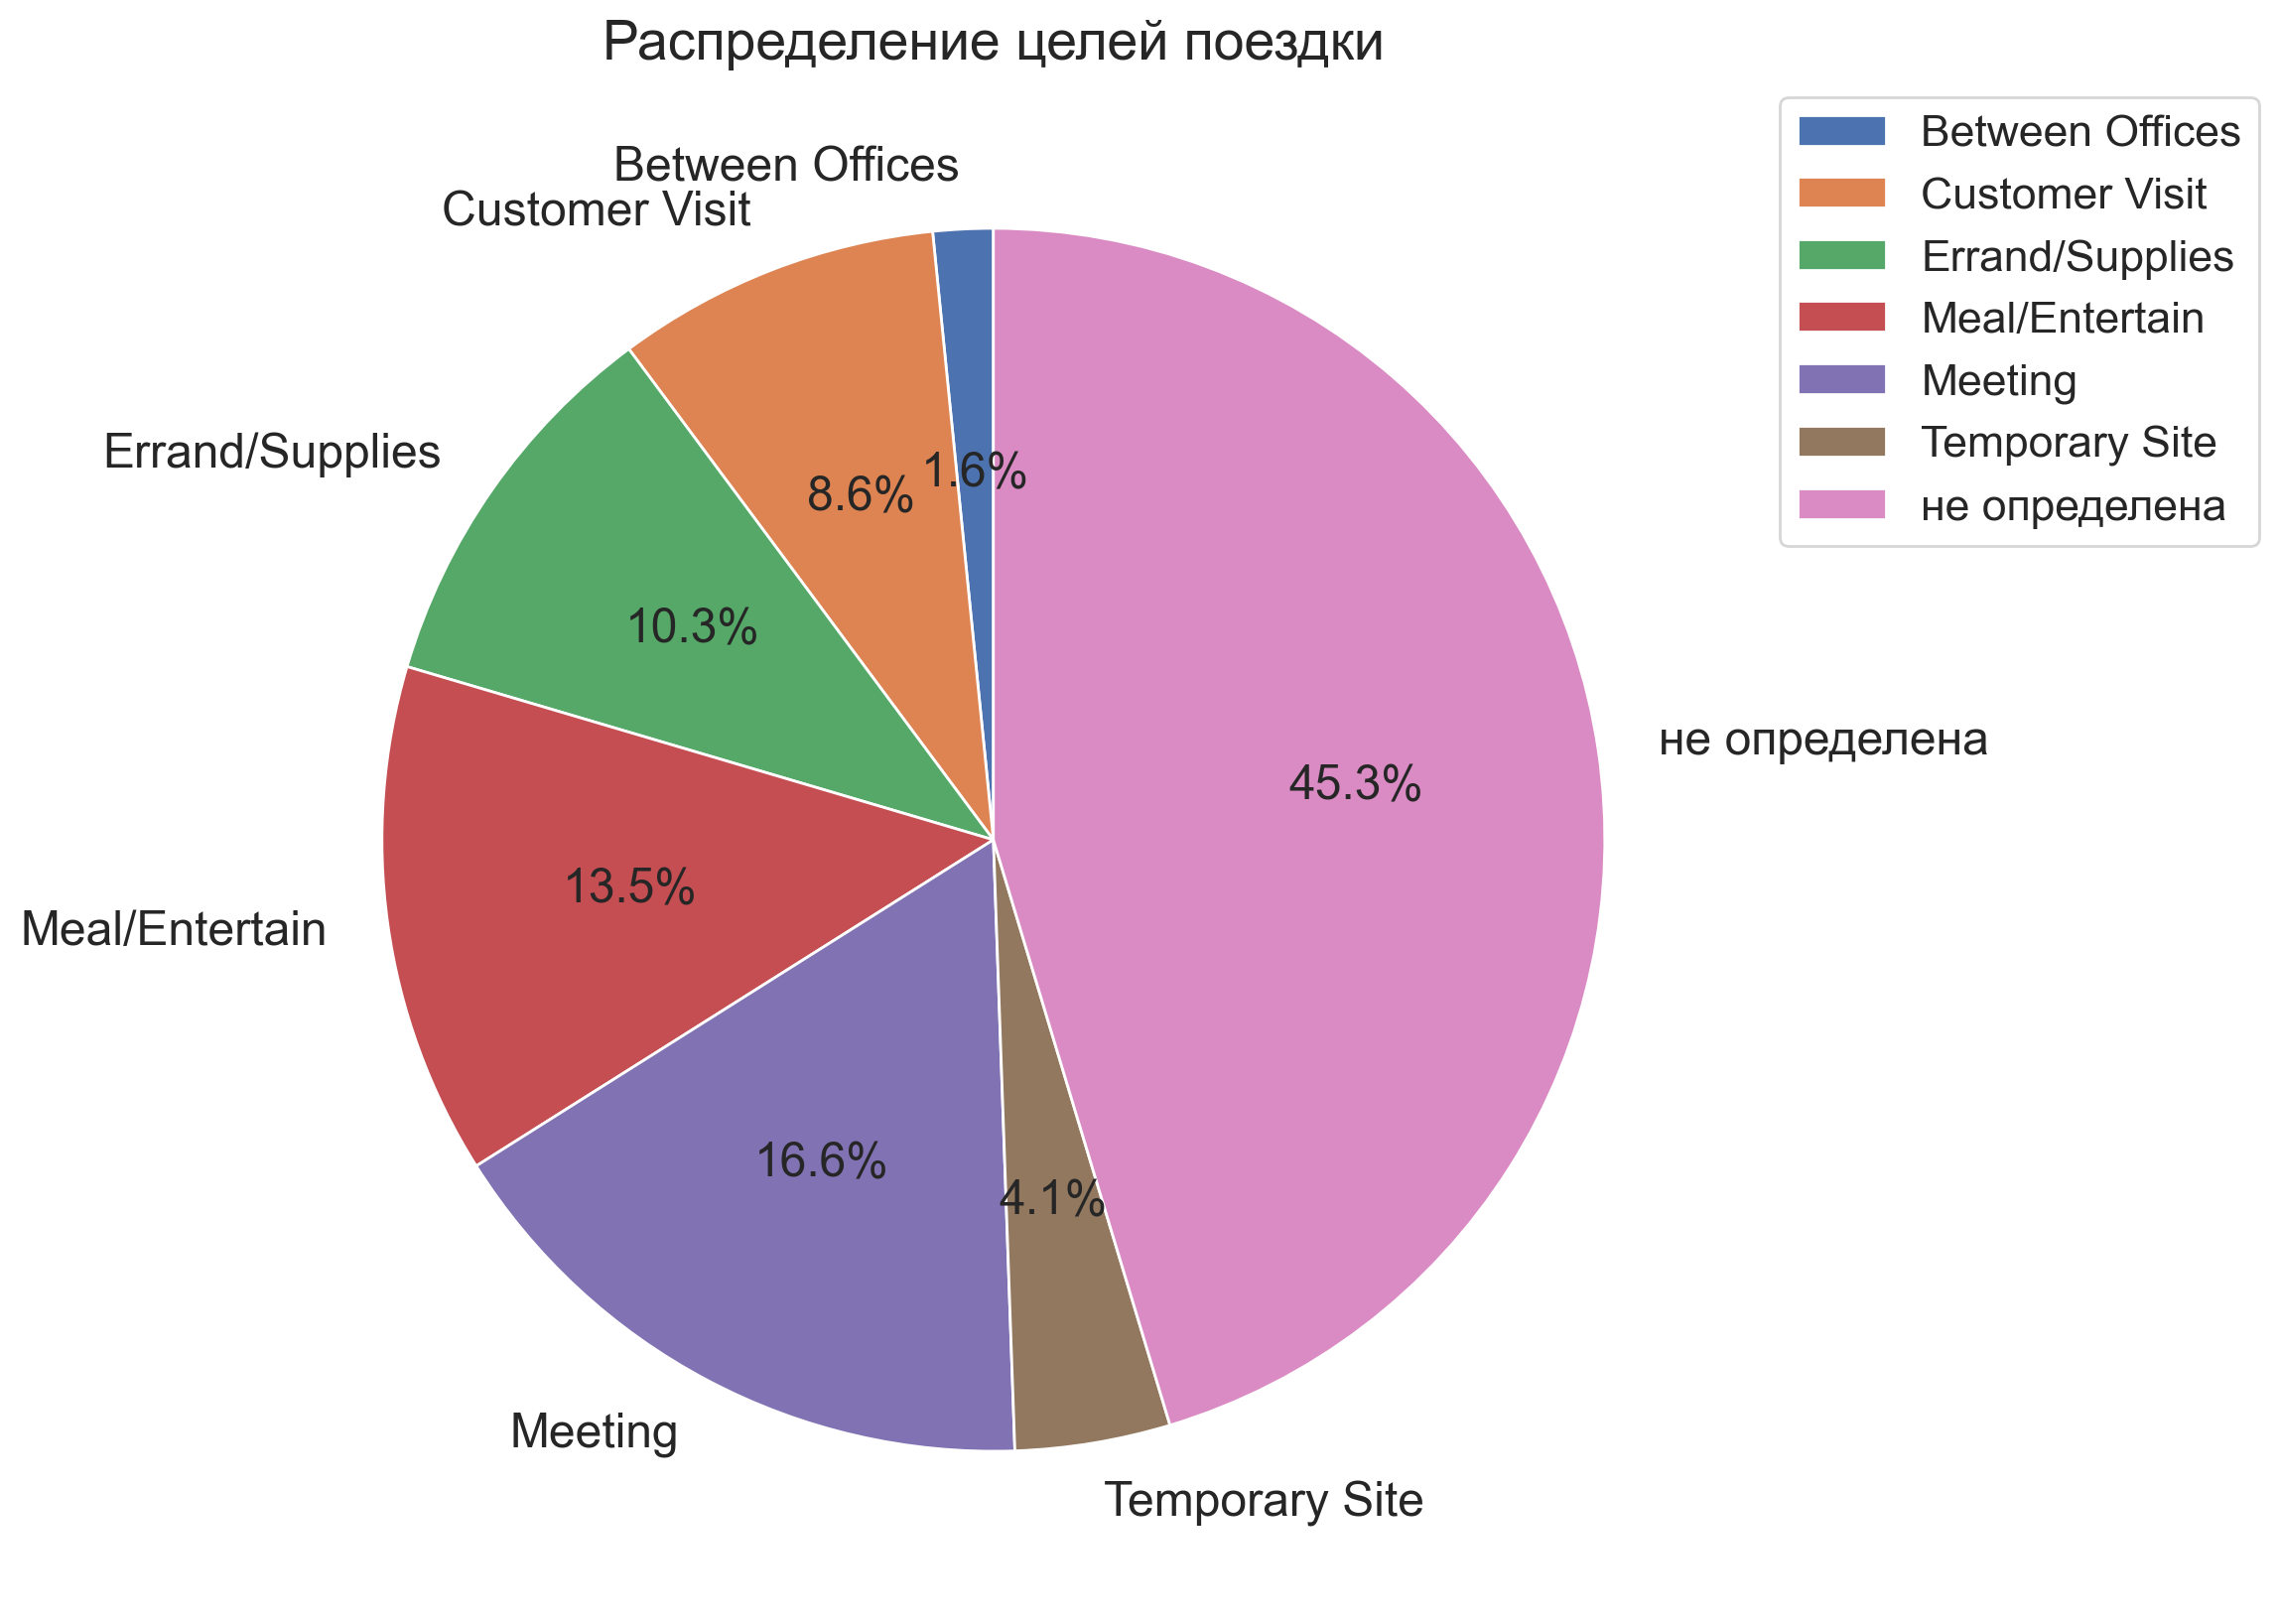

In [17]:
trips_per_purpose = trips['PURPOSE'].value_counts()
purpose_share = trips_per_purpose[trips_per_purpose >= 5]
purpose_share = purpose_share.sort_index()

plt.figure(figsize=(20, 10))
plt.pie(purpose_share, labels=purpose_share.index,
        autopct='%1.1f%%', textprops={'size': 'x-large'},
        startangle=90)
plt.title('Распределение целей поездки', fontsize=20)
plt.legend(fontsize=16, bbox_to_anchor=(1, 1))
plt.show()

Цели отсортированы по алфавиту. Убраны Moving, Airport/Travel, Charity ($) и Commute — вместе 8 поездок. Почти половина диаграммы (45.3 %) — поездки без цели. Среди известных целей больше всего встреч (16.6 %), питания и развлечений (13.5 %) и поручений (10.3 %). На поездки к клиентам приходится 8.6 %, на временные площадки — 4.1 %, между офисами — 1.6 %.

## 7. Hexagonal binning plot

Строю плотность поездок по расстоянию и длительности. Чтобы редкие дальние поездки не растягивали оси, беру поездки до 30 миль и до 60 минут. Пустые шестиугольники не закрашиваются (`mincnt=1`).

Поездок до 30 миль и 60 минут: 1016 из 1080


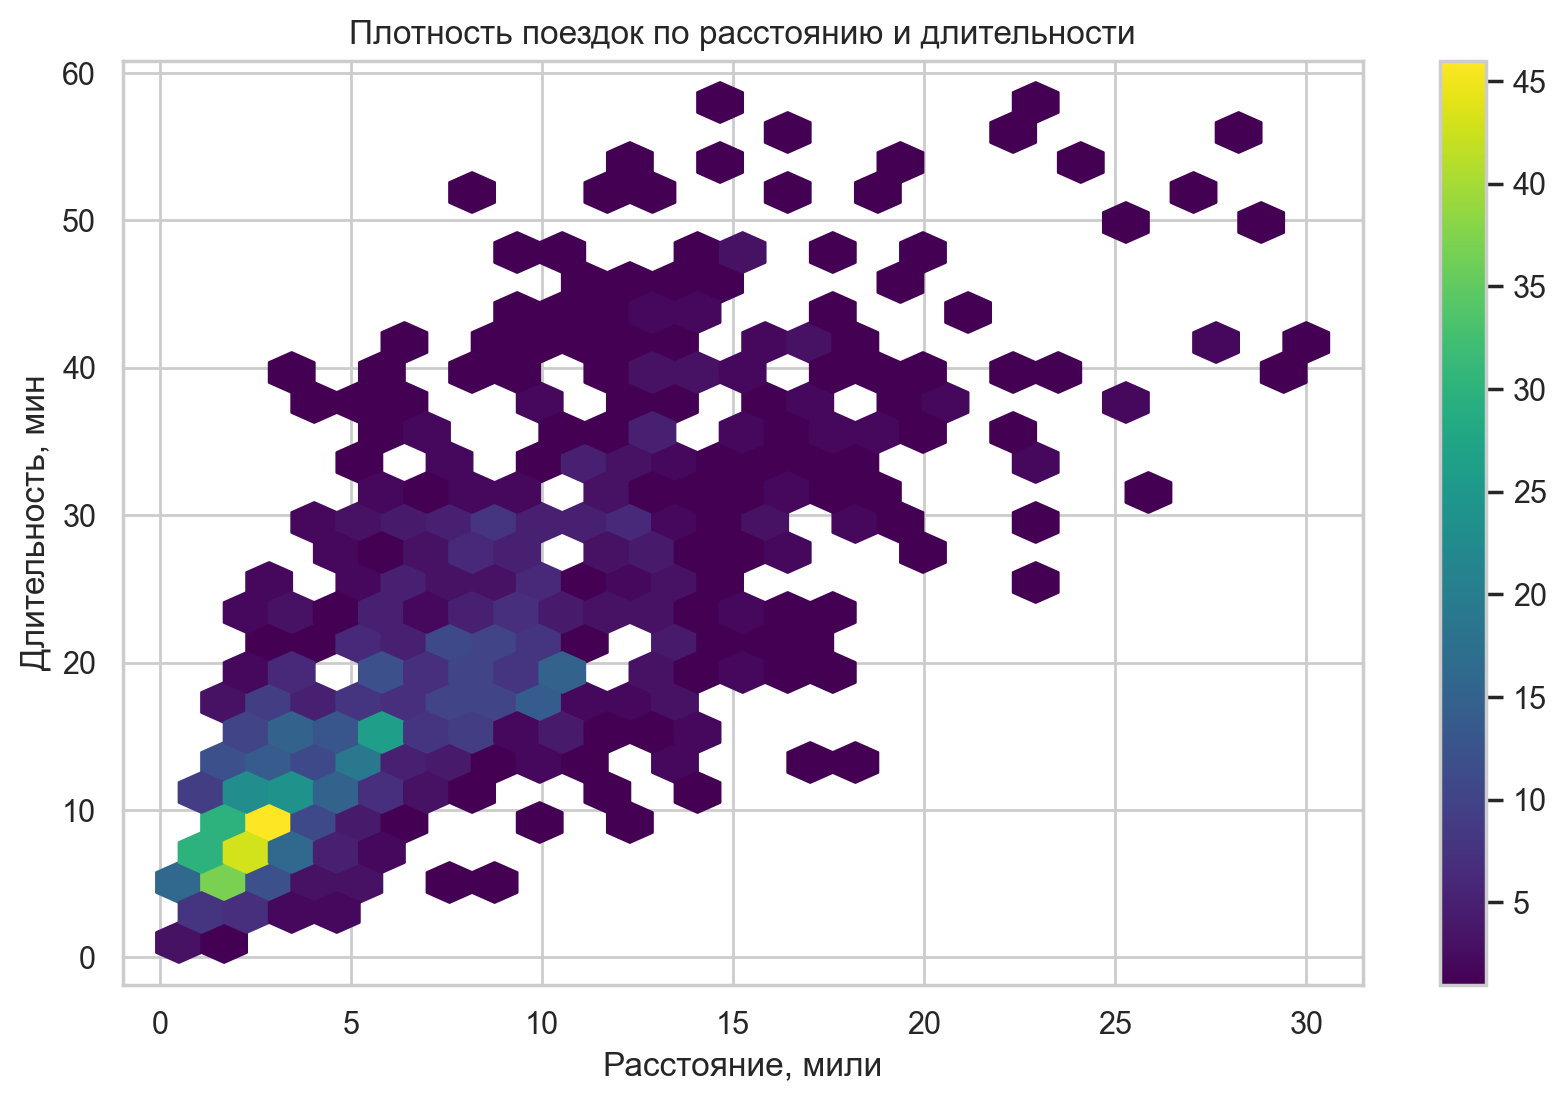

In [18]:
typical = trips.query('MILES <= 30 and TIME <= 60')
print(f'Поездок до 30 миль и 60 минут: {len(typical)} из {len(trips)}')

ax = typical.plot.hexbin(x='MILES', y='TIME', gridsize=25, mincnt=1, cmap='viridis',
                         figsize=(10, 6), sharex=False)
ax.set(xlabel=LABELS['MILES'], ylabel=LABELS['TIME'],
       title='Плотность поездок по расстоянию и длительности')
plt.show()

В выбранную область попадают 94 % поездок. Самые плотные ячейки — 1–4 мили и 5–10 минут, это типичная поездка по городу. Дальше плотность вытягивается полосой вдоль диагонали: у поездок на 9–11 миль половина длится от 18 до 29 минут. С расстоянием полоса расширяется — время поездки на одно и то же расстояние разбросано сильнее.

## 8. Диаграмма размаха стоимости

Matplotlib, столбец `PRICE`.

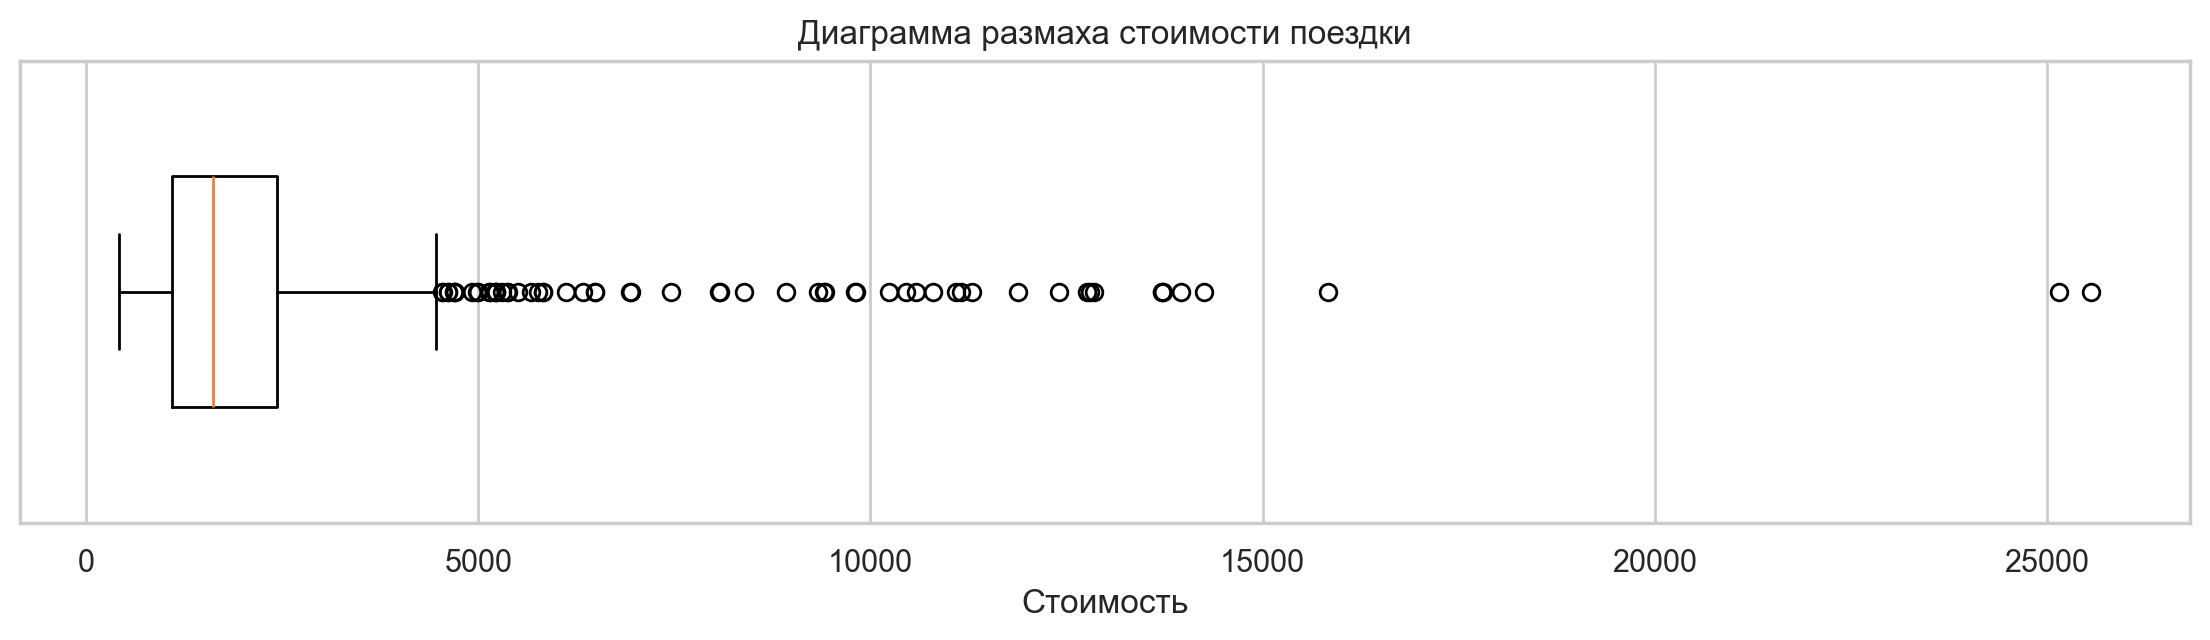

In [19]:
fig, ax = plt.subplots(figsize=(14, 3))
ax.boxplot(trips['PRICE'], vert=False, widths=0.5)
ax.set(xlabel=LABELS['PRICE'], yticks=[], title='Диаграмма размаха стоимости поездки')
plt.show()

In [20]:
q1, median, q3 = trips['PRICE'].quantile([0.25, 0.5, 0.75])
outlier_bound = q3 + 1.5 * (q3 - q1)
print(f'Q1 = {q1:.0f}, медиана = {median:.0f}, Q3 = {q3:.0f}')
print(f'Граница выбросов: {outlier_bound:.0f}')
print('Выбросов:', (trips['PRICE'] > outlier_bound).sum())

Q1 = 1087, медиана = 1611, Q3 = 2437
Граница выбросов: 4462
Выбросов: 59


Половина поездок стоит от 1087 до 2437, медиана 1611 ближе к левому краю ящика. Левый ус короткий и заканчивается на минимуме 412, выбросов снизу нет. Справа за границей 4462 лежат 59 выбросов (5.5 % поездок), самые дорогие — две поездки около 25 000. Это не ошибки: 53 из 59 выбросов — поездки дальше 15 миль, а две самые дорогие длились около 5.5 часа. Распределение стоимости сильно скошено вправо, как и на гистограмме.

## 9. Категория дальности поездки

Добавляю категорию по расстоянию: короткая — до 5 миль, средняя — от 5 до 15, дальняя — больше 15. Границы круглые и близки к медиане (6 миль) и 90-му процентилю (17 миль) расстояния, поэтому дальними оказываются 13 % самых длинных поездок.

In [21]:
trips['DISTANCE_CATEGORY'] = pd.cut(
    trips['MILES'],
    bins=[0, 5, 15, np.inf],
    labels=['короткая', 'средняя', 'дальняя'],
)
trips['DISTANCE_CATEGORY'].value_counts()

DISTANCE_CATEGORY
средняя     469
короткая    467
дальняя     144
Name: count, dtype: int64

Коротких и средних поездок почти поровну (467 и 469), дальних — 144. Рядом с расстоянием строю стоимость по тем же категориям, чтобы проверить, насколько дальность определяет цену. Оба графика в логарифмической шкале.

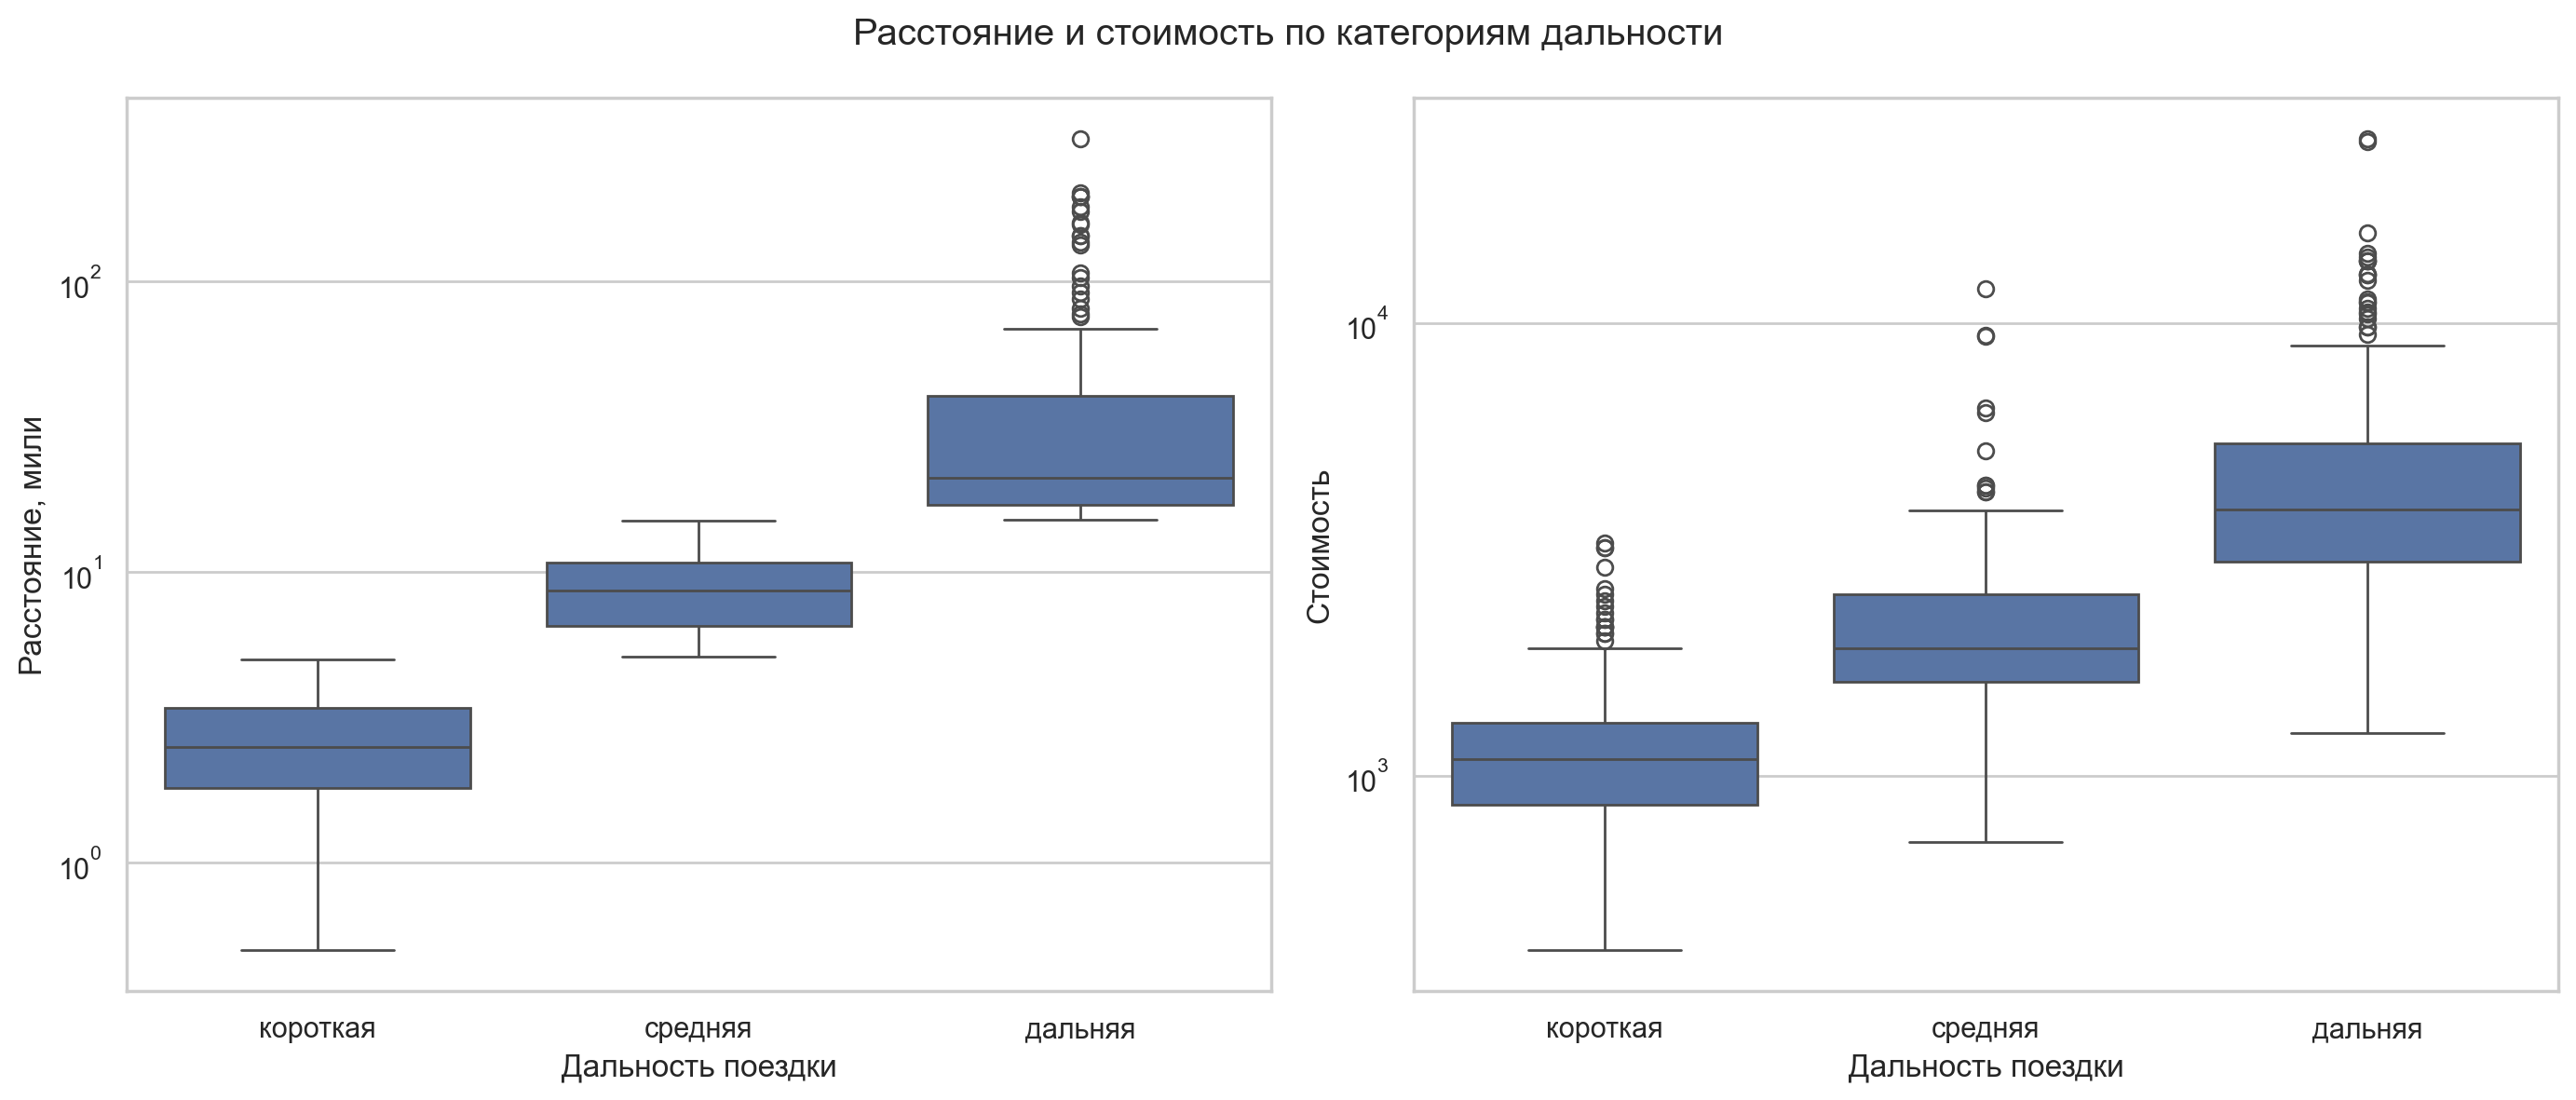

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, column in zip(axes, ['MILES', 'PRICE']):
    sns.boxplot(data=trips, x='DISTANCE_CATEGORY', y=column, ax=ax)
    ax.set(yscale='log', xlabel='Дальность поездки', ylabel=LABELS[column])

fig.suptitle('Расстояние и стоимость по категориям дальности')
fig.tight_layout()
plt.show()

Ящики расстояния не пересекаются — так задуманы категории. Медианы: 2.5, 8.6 и 21 миля. Внутри дальних поездок разброс самый большой: от 15 до 310 миль, выше 70 миль идут выбросы.

По стоимости медианы растут так же: 1087, 1913 и 3864. Ящики стоимости не пересекаются, но усы и выбросы соседних категорий перекрываются: 18 коротких поездок дороже медианы средних. Стоимость считается по времени, а короткая поездка может затянуться, например из-за пробок.

## 10. Диаграммы размаха по другим категориям

Скорость по категории поездки — pandas.

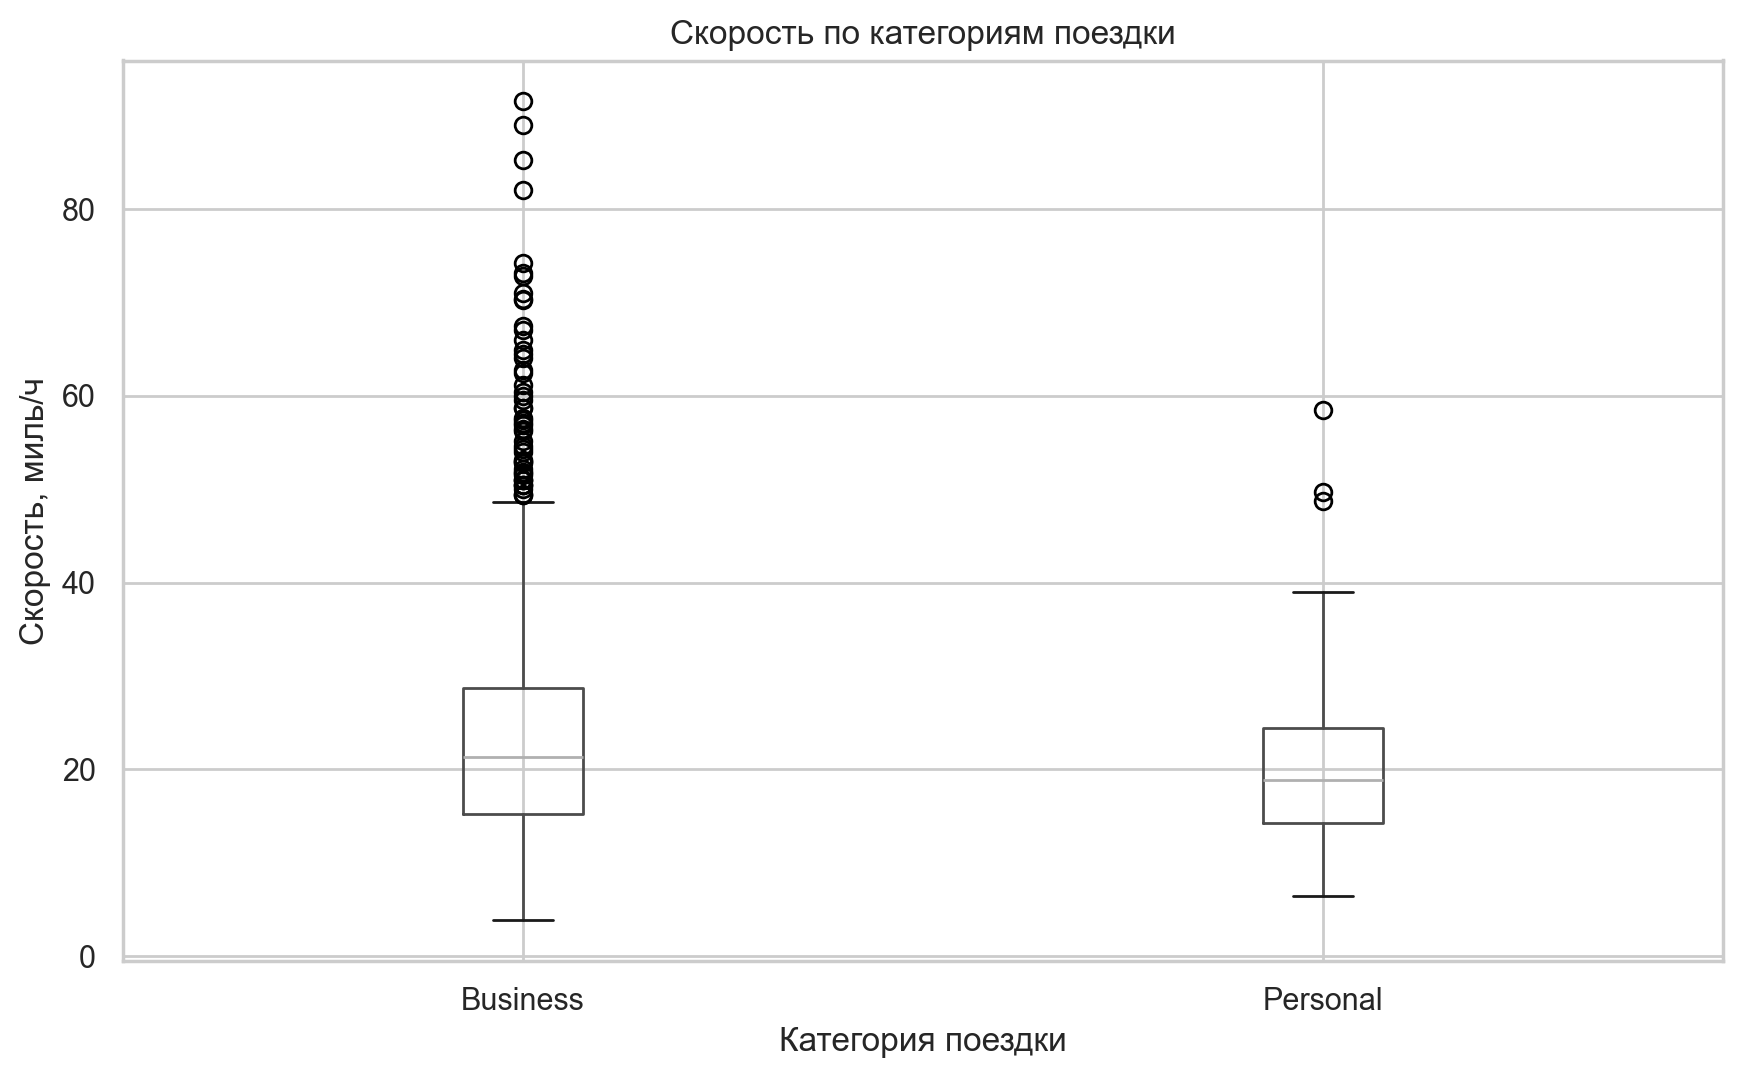

In [23]:
ax = trips.boxplot(column='SPEED', by='CATEGORY', figsize=(10, 6))
ax.set(xlabel='Категория поездки', ylabel=LABELS['SPEED'],
       title='Скорость по категориям поездки')
plt.suptitle('')
plt.show()

Медиана скорости деловых поездок 21.3 мили/ч, личных — 18.9. Половина деловых поездок идёт со скоростью 15–29 миль/ч, личных — 14–24. Разница небольшая, к тому же личных поездок всего 77. Самая высокая скорость личной поездки — 58.4 мили/ч.

У деловых поездок 52 выброса вверх, выше 48.6 мили/ч, и они двух видов. Из них 23 — поездки длиннее 40 миль, то есть междугородние поездки по трассе, например Jacksonville — Kissimmee: 201 миля со средней скоростью 73 мили/ч. Остальные 29 — поездки не длиннее 23 миль и не дольше 26 минут. Часть из них правдоподобна, это поездки по шоссе между соседними городами со скоростью около 50 миль/ч. Но самые быстрые явно ошибочны: 18.3 мили за 12 минут (91.5 мили/ч), 8.9 мили за 6 минут (89 миль/ч), 7.1 мили за 5 минут (85 миль/ч). Скорее всего, длительность у них записана с той же ошибкой, что и у поездок, удалённых в разделе 2: порог 100 миль/ч там выбран с запасом, и такие поездки остались.

Расстояние по цели поездки — seaborn. Показаны цели, у которых не меньше 5 поездок, отсортированные по медиане расстояния, ось расстояния логарифмическая.

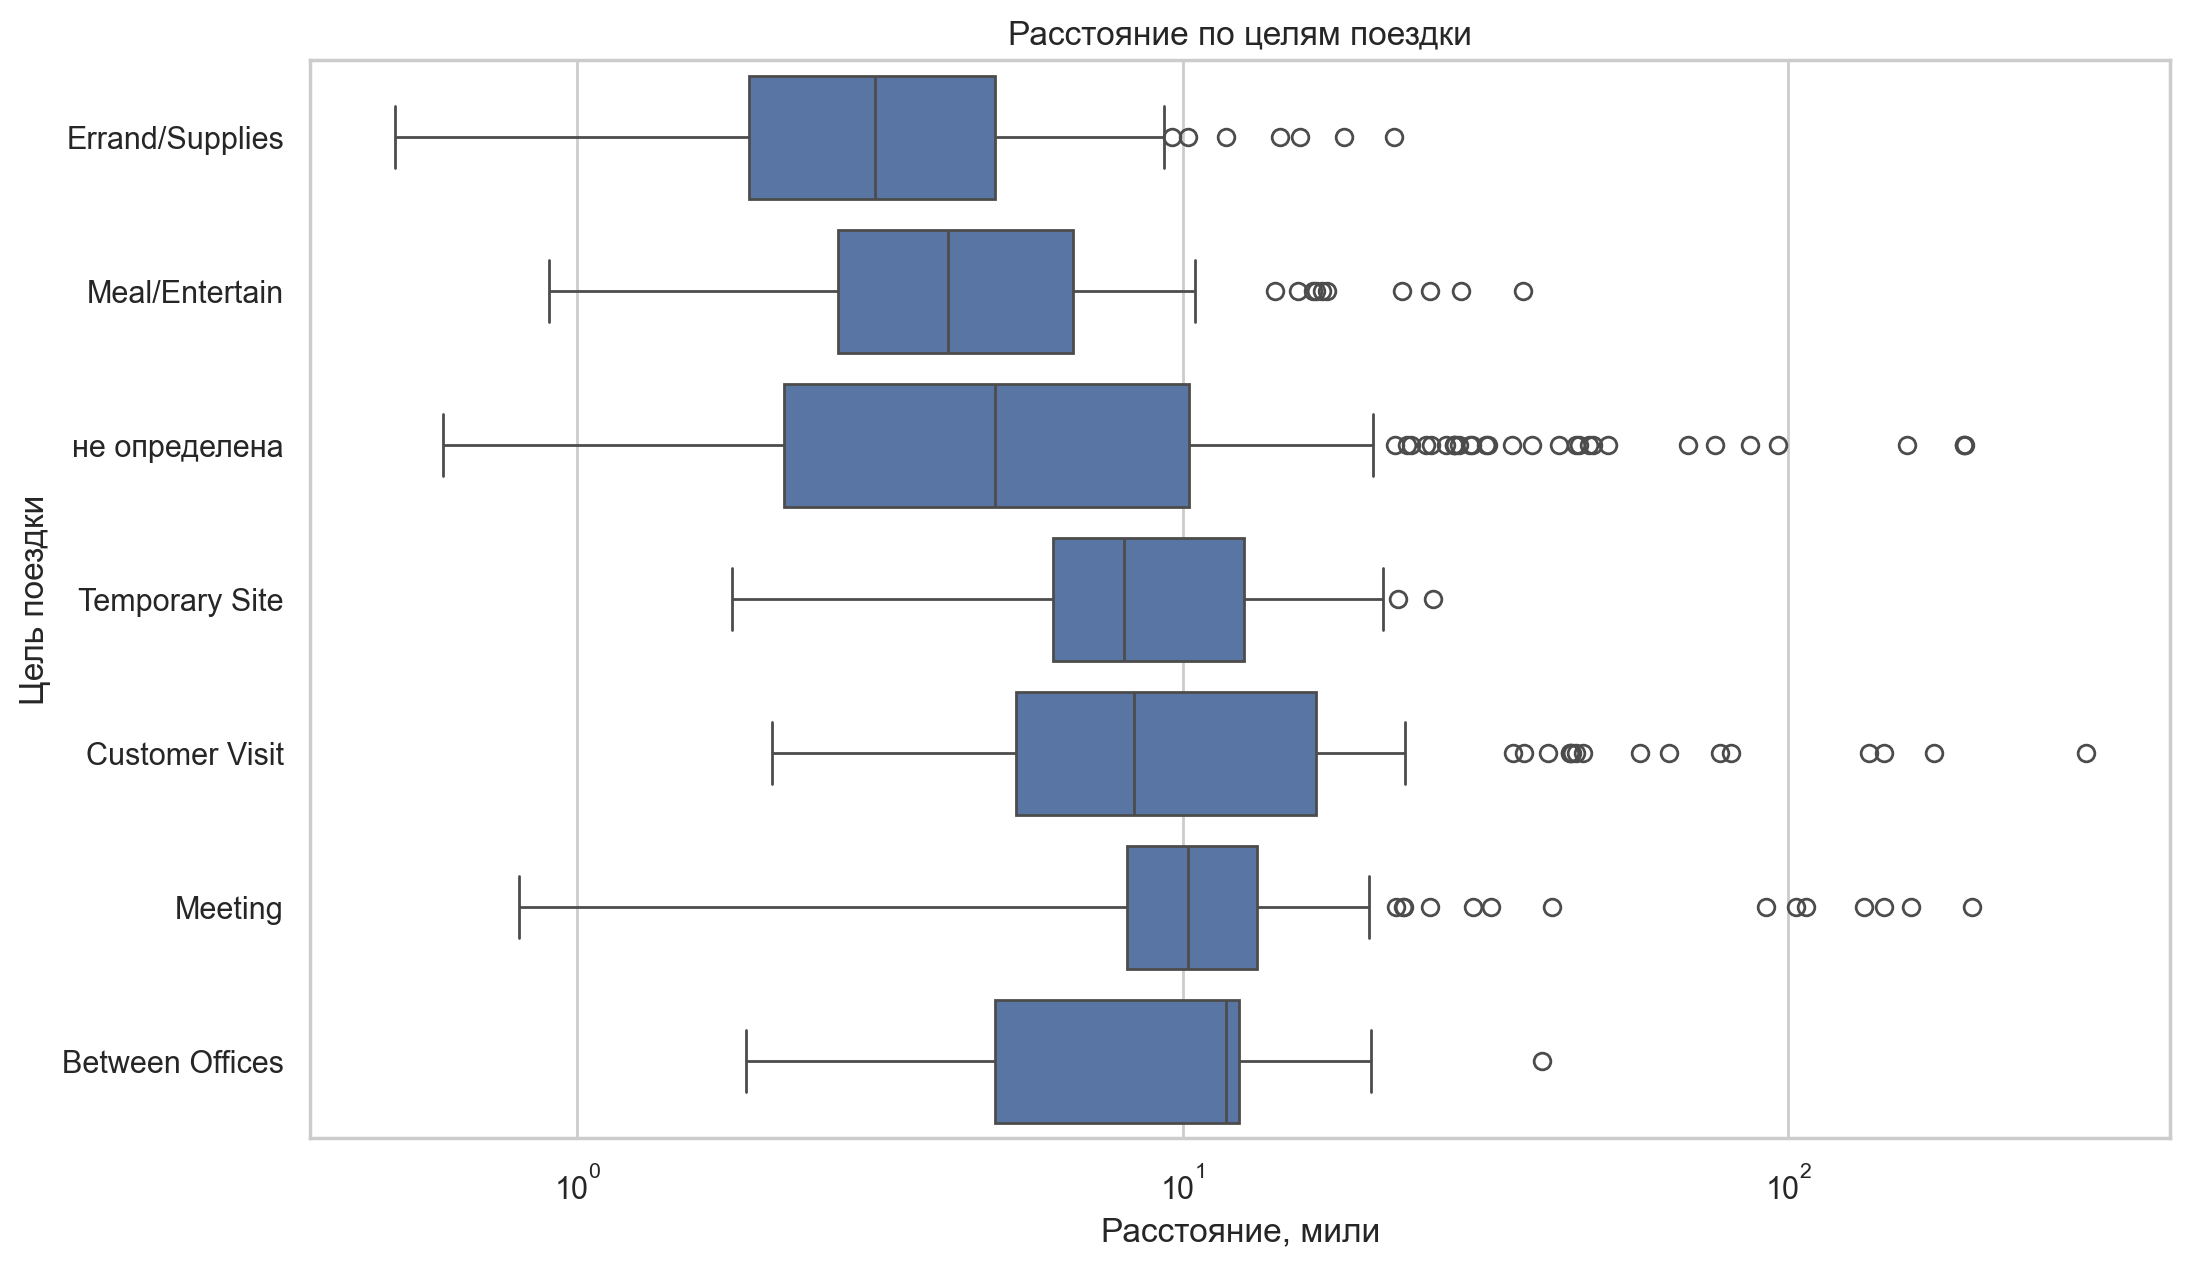

In [24]:
trips_per_purpose = trips['PURPOSE'].value_counts()
frequent_purposes = trips_per_purpose[trips_per_purpose >= 5].index
frequent_trips = trips[trips['PURPOSE'].isin(frequent_purposes)]
median_miles = frequent_trips.groupby('PURPOSE')['MILES'].median()
purpose_order = median_miles.sort_values().index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=frequent_trips, x='MILES', y='PURPOSE', order=purpose_order,
            ax=ax)
ax.set(xscale='log', xlabel=LABELS['MILES'], ylabel='Цель поездки',
       title='Расстояние по целям поездки')
plt.show()

Цели делятся на две группы. Короткие — Errand/Supplies (медиана 3.1 мили) и Meal/Entertain (4.1): поручения и обеды обычно рядом. Длинные — Temporary Site (8.0), Customer Visit (8.3), Meeting (10.2) и Between Offices (11.8). У Customer Visit и Meeting много выбросов справа, до 100–300 миль: к клиентам и на встречи иногда ездят в другой город. Поэтому в задании 2 средние у этих целей получились намного больше медиан. У поездок без цели («не определена», медиана 4.9) самый широкий ящик: в эту группу попали поездки с разными целями.

## 11. Удаление выбросов стоимости

На диаграмме размаха стоимости в разделе 8 было 59 выбросов. Выбросом считается значение дальше 1.5 · IQR от ящика, то есть меньше $Q_1 - 1.5 \cdot IQR$ или больше $Q_3 + 1.5 \cdot IQR$. После удаления выбросов квартили сдвигаются, границы сужаются, и часть оставшихся поездок снова оказывается за ними. Поэтому удаление повторяю, пока выбросов не останется. Квартили считаются тем же способом, что и в `boxplot`, так что после последней итерации на диаграмме выбросов не будет.

In [25]:
def remove_outliers(data, column):
    steps = []
    while True:
        q1, q3 = data[column].quantile([0.25, 0.75])
        lower = q1 - 1.5 * (q3 - q1)
        upper = q3 + 1.5 * (q3 - q1)
        inside = data[column].between(lower, upper)
        if inside.all():
            iterations = pd.RangeIndex(1, len(steps) + 1, name='Итерация')
            return data, pd.DataFrame(steps, index=iterations)
        steps.append({
            'Поездок': len(data),
            'Нижняя граница': lower,
            'Верхняя граница': upper,
            'Удалено': (~inside).sum(),
        })
        data = data[inside]


price_cleaned, price_steps = remove_outliers(trips, 'PRICE')
print(f'Итераций: {len(price_steps)}')
print(f'Осталось поездок: {len(price_cleaned)} из {len(trips)}')
price_steps.round(0)

Итераций: 4
Осталось поездок: 978 из 1080


,Поездок,Нижняя граница,Верхняя граница,Удалено
Итерация,,,,
1,1080,-938.0,4462.0,59
2,1021,-599.0,3897.0,23
3,998,-460.0,3665.0,11
4,987,-377.0,3527.0,9


Понадобилось 4 итерации, на пятой проверке выбросов уже нет. Удалено 102 поездки (9.4 %), осталось 978. Верхняя граница с каждой итерацией сдвигается влево: 4462, 3897, 3665, 3527, а удаляется всё меньше поездок: 59, 23, 11, 9. Нижняя граница всё время отрицательная, поэтому снизу ничего не удаляется.

Стоимость считается по длительности, так что граница по стоимости — это граница по времени: удалены все поездки длиннее 42 минут. Коротких поездок среди удалённых нет, медиана их расстояния — 25.5 мили. В разделе 8 было видно, что это не ошибки, а настоящие долгие поездки. Повторное удаление срезает правый хвост распределения: после каждой итерации граница считается уже по укороченным данным и снова отрезает часть хвоста.

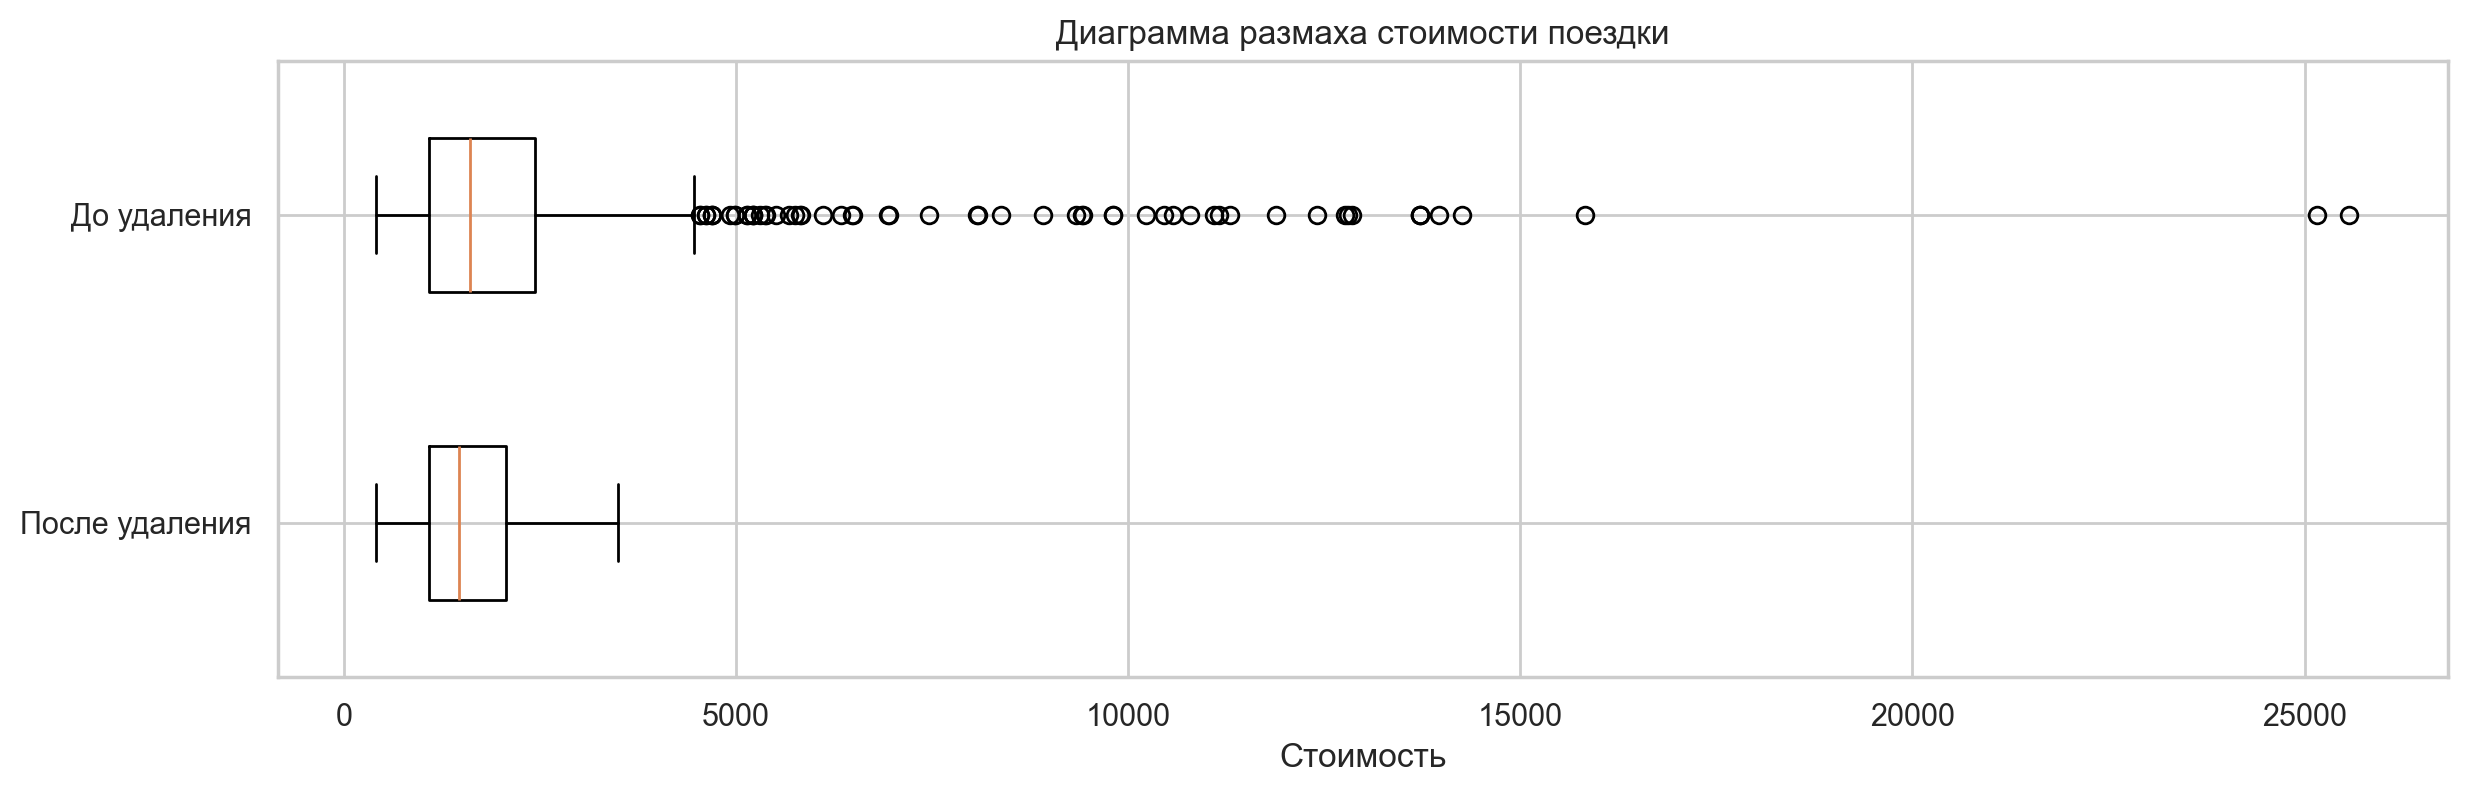

In [26]:
prices = {'До удаления': trips['PRICE'], 'После удаления': price_cleaned['PRICE']}

fig, ax = plt.subplots(figsize=(14, 4))
ax.boxplot(prices.values(), tick_labels=prices.keys(), vert=False, widths=0.5)
ax.set(xlabel=LABELS['PRICE'], title='Диаграмма размаха стоимости поездки')
ax.invert_yaxis()
plt.show()

In [27]:
price_cleaned['PRICE'].describe().round(0)

count     978.0
mean     1624.0
std       723.0
min       412.0
25%      1087.0
50%      1463.0
75%      2063.0
max      3493.0
Name: PRICE, dtype: float64

Ящик сузился: Q3 упал с 2437 до 2063, медиана — с 1611 до 1463, а Q1 остался на 1087. Правый ус заканчивается на 3493, выбросов нет. Стандартное отклонение уменьшилось почти втрое, с 2093 до 723, и среднее (1624) стало близко к медиане. Асимметрия при этом осталась: правый ус вдвое длиннее левого.

Дальше перестраиваю остальные диаграммы размаха по очищенной таблице `price_cleaned`. Сначала смотрю, сколько поездок осталось в категориях дальности:

In [28]:
price_cleaned['DISTANCE_CATEGORY'].value_counts()

DISTANCE_CATEGORY
короткая    467
средняя     443
дальняя      68
Name: count, dtype: int64

Все удалённые поездки — средние и дальние. Коротких осталось столько же, 467, средних — 443 вместо 469, а дальних — 68 вместо 144. Больше половины дальних поездок оказались выбросами по стоимости, самая длинная из оставшихся — 30.2 мили.

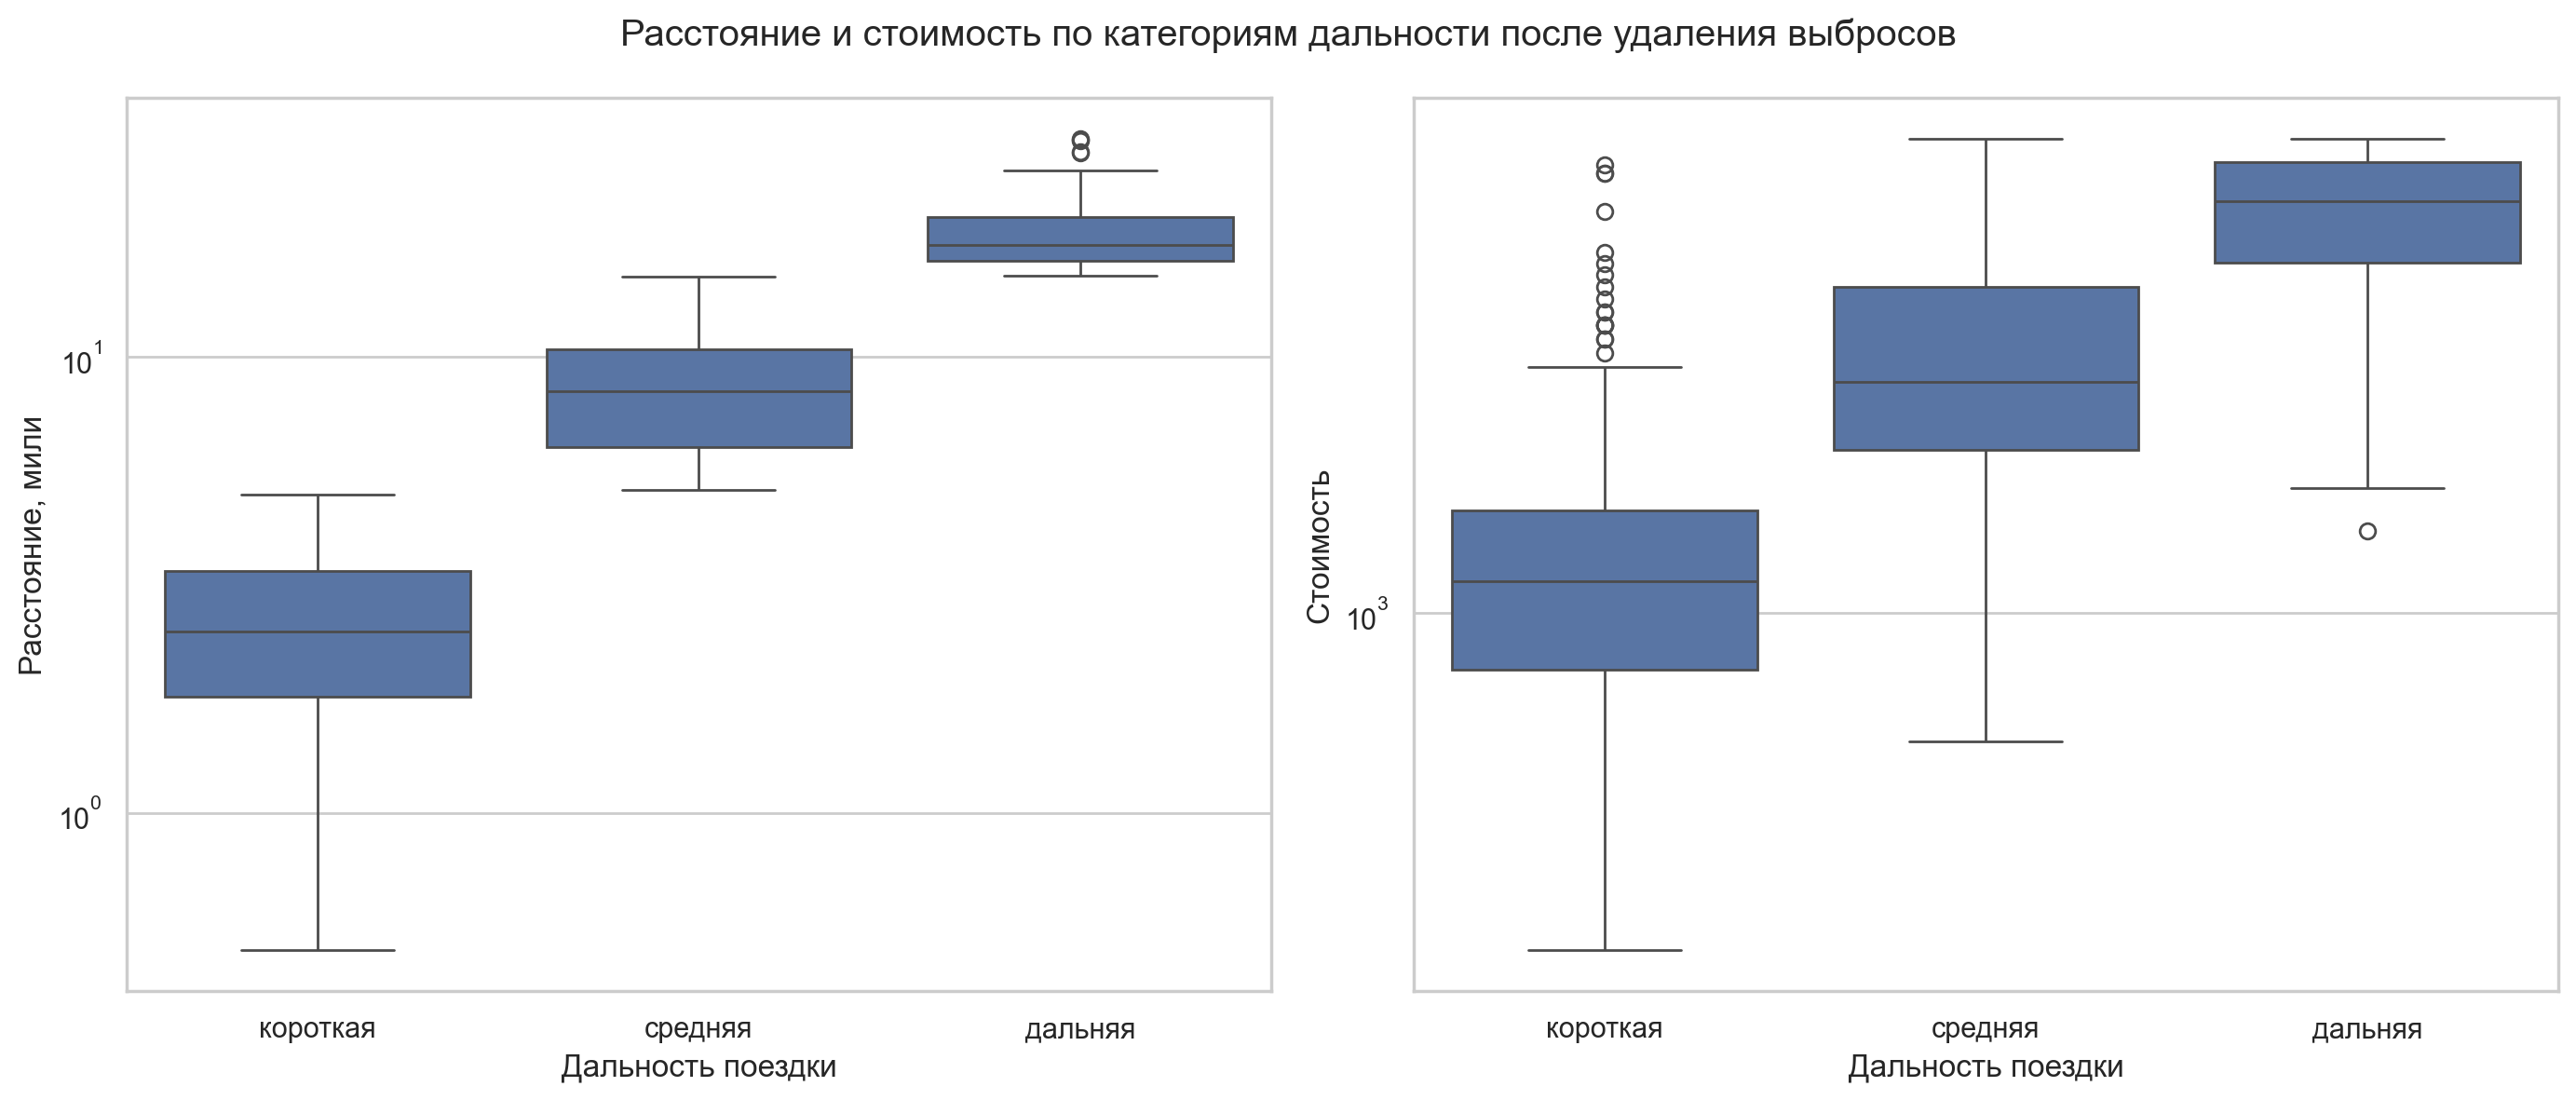

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

for ax, column in zip(axes, ['MILES', 'PRICE']):
    sns.boxplot(data=price_cleaned, x='DISTANCE_CATEGORY', y=column, ax=ax)
    ax.set(yscale='log', xlabel='Дальность поездки', ylabel=LABELS[column])

fig.suptitle('Расстояние и стоимость по категориям дальности после удаления выбросов')
fig.tight_layout()
plt.show()

Ящики расстояния по-прежнему не пересекаются. У дальних поездок медиана снизилась с 21 до 17.6 мили, выбросов осталось 5 вместо 21. Короткие и средние поездки почти не изменились.

У стоимости дальних поездок медиана упала с 3864 до 2964, третий квартиль — 3283, а верхний ус доходит до общей границы 3493: стоимость дальних поездок теперь обрезана сверху. Снизу у дальних поездок появился выброс 1242. Это поездка 18.3 мили за 12 минут со скоростью 91.5 мили/ч из раздела 10: до удаления на ней заканчивался нижний ус, а теперь ящик сузился, и она оказалась за границей. У средних поездок медиана 1839 вместо 1913, выбросов у них больше нет. А у коротких поездок как было 18 выбросов, так и осталось. Все короткие поездки дешевле общей границы, но внутри своей категории дорогие короткие поездки остаются выбросами, потому что ящик коротких поездок лежит ниже. Удаление выбросов по всей таблице не убирает выбросы внутри групп.

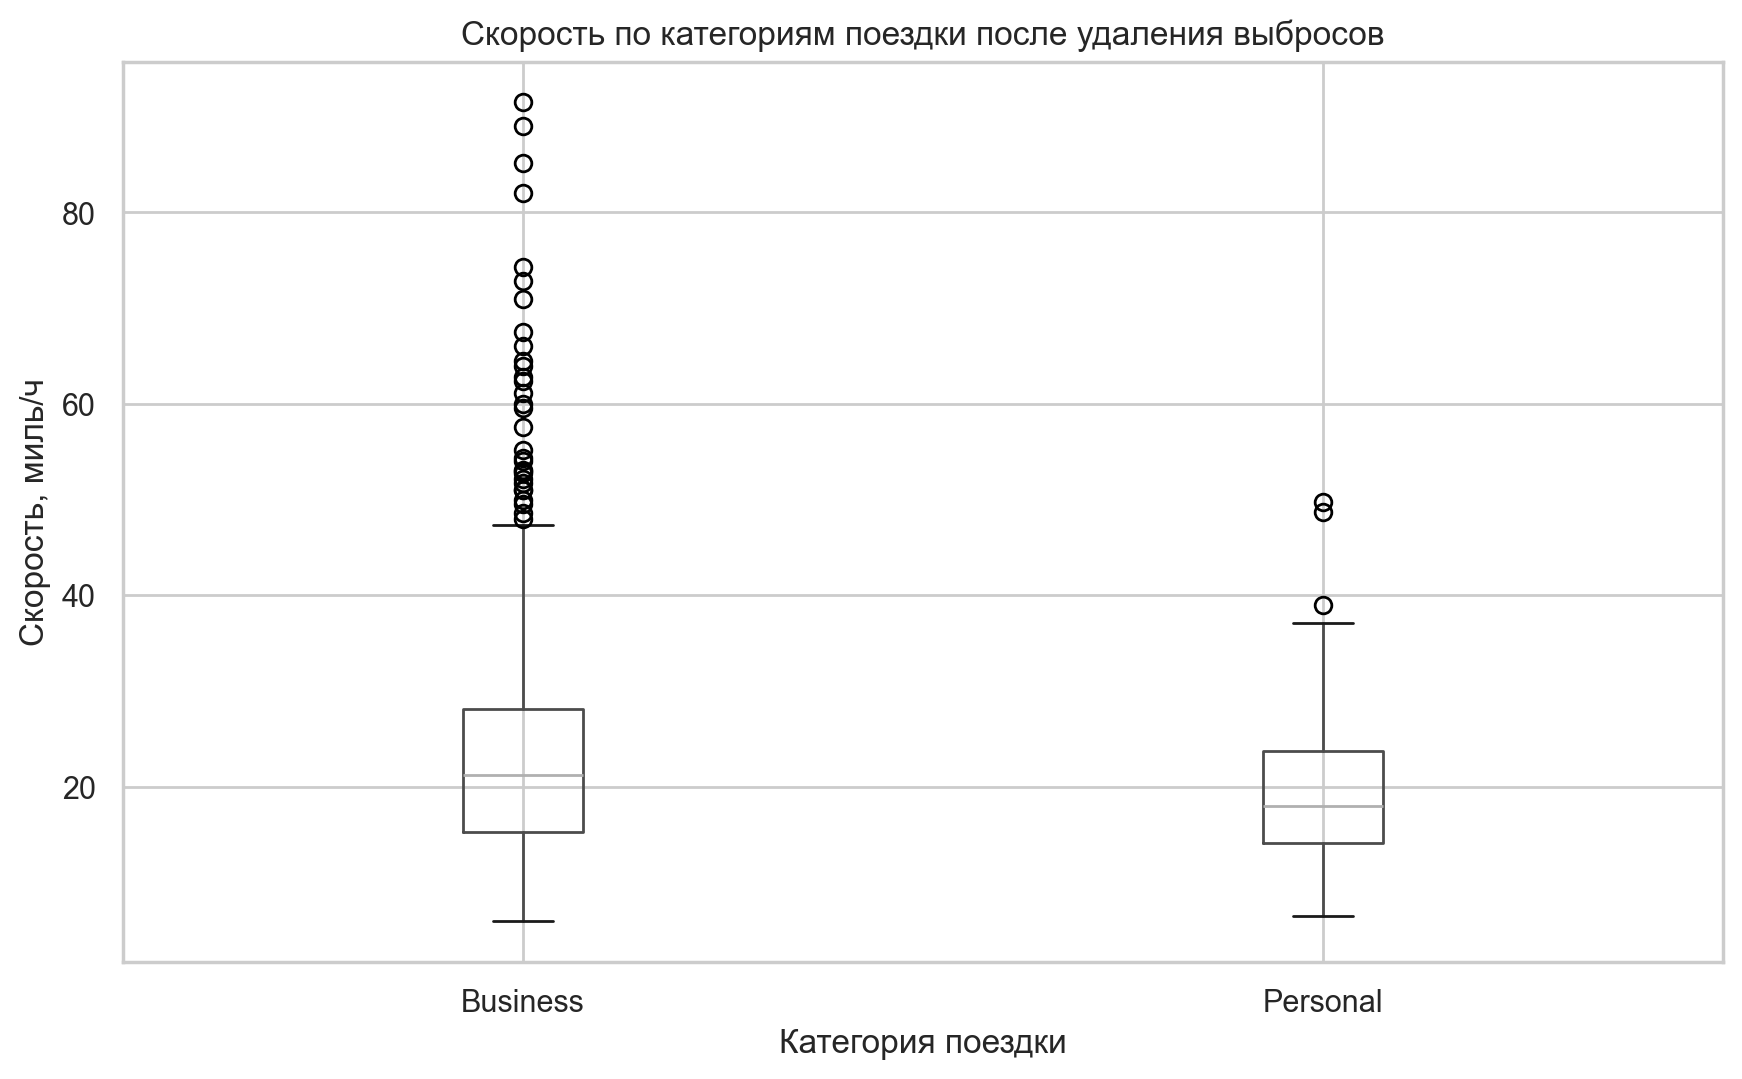

In [30]:
ax = price_cleaned.boxplot(column='SPEED', by='CATEGORY', figsize=(10, 6))
ax.set(xlabel='Категория поездки', ylabel=LABELS['SPEED'],
       title='Скорость по категориям поездки после удаления выбросов')
plt.suptitle('')
plt.show()

Медианы скорости почти не изменились: 21.2 мили/ч у деловых поездок и 18.0 у личных. Выбросов у деловых поездок стало 31 вместо 52. Удалены все 23 междугородние поездки из раздела 10: они длились больше 42 минут и поэтому оказались выбросами по стоимости. Остались 29 коротких быстрых поездок, в том числе самые быстрые, до 91.5 мили/ч, и к ним добавились 2 новых выброса, так как граница опустилась до 47.3 мили/ч. У личных поездок выбросов по-прежнему 3, максимум снизился с 58.4 до 49.7 мили/ч. Корреляция скорости со стоимостью слабая, около 0.2, но удаление по стоимости убрало почти половину выбросов скорости: оно отрезает долгие поездки, а половина быстрых поездок — междугородние.

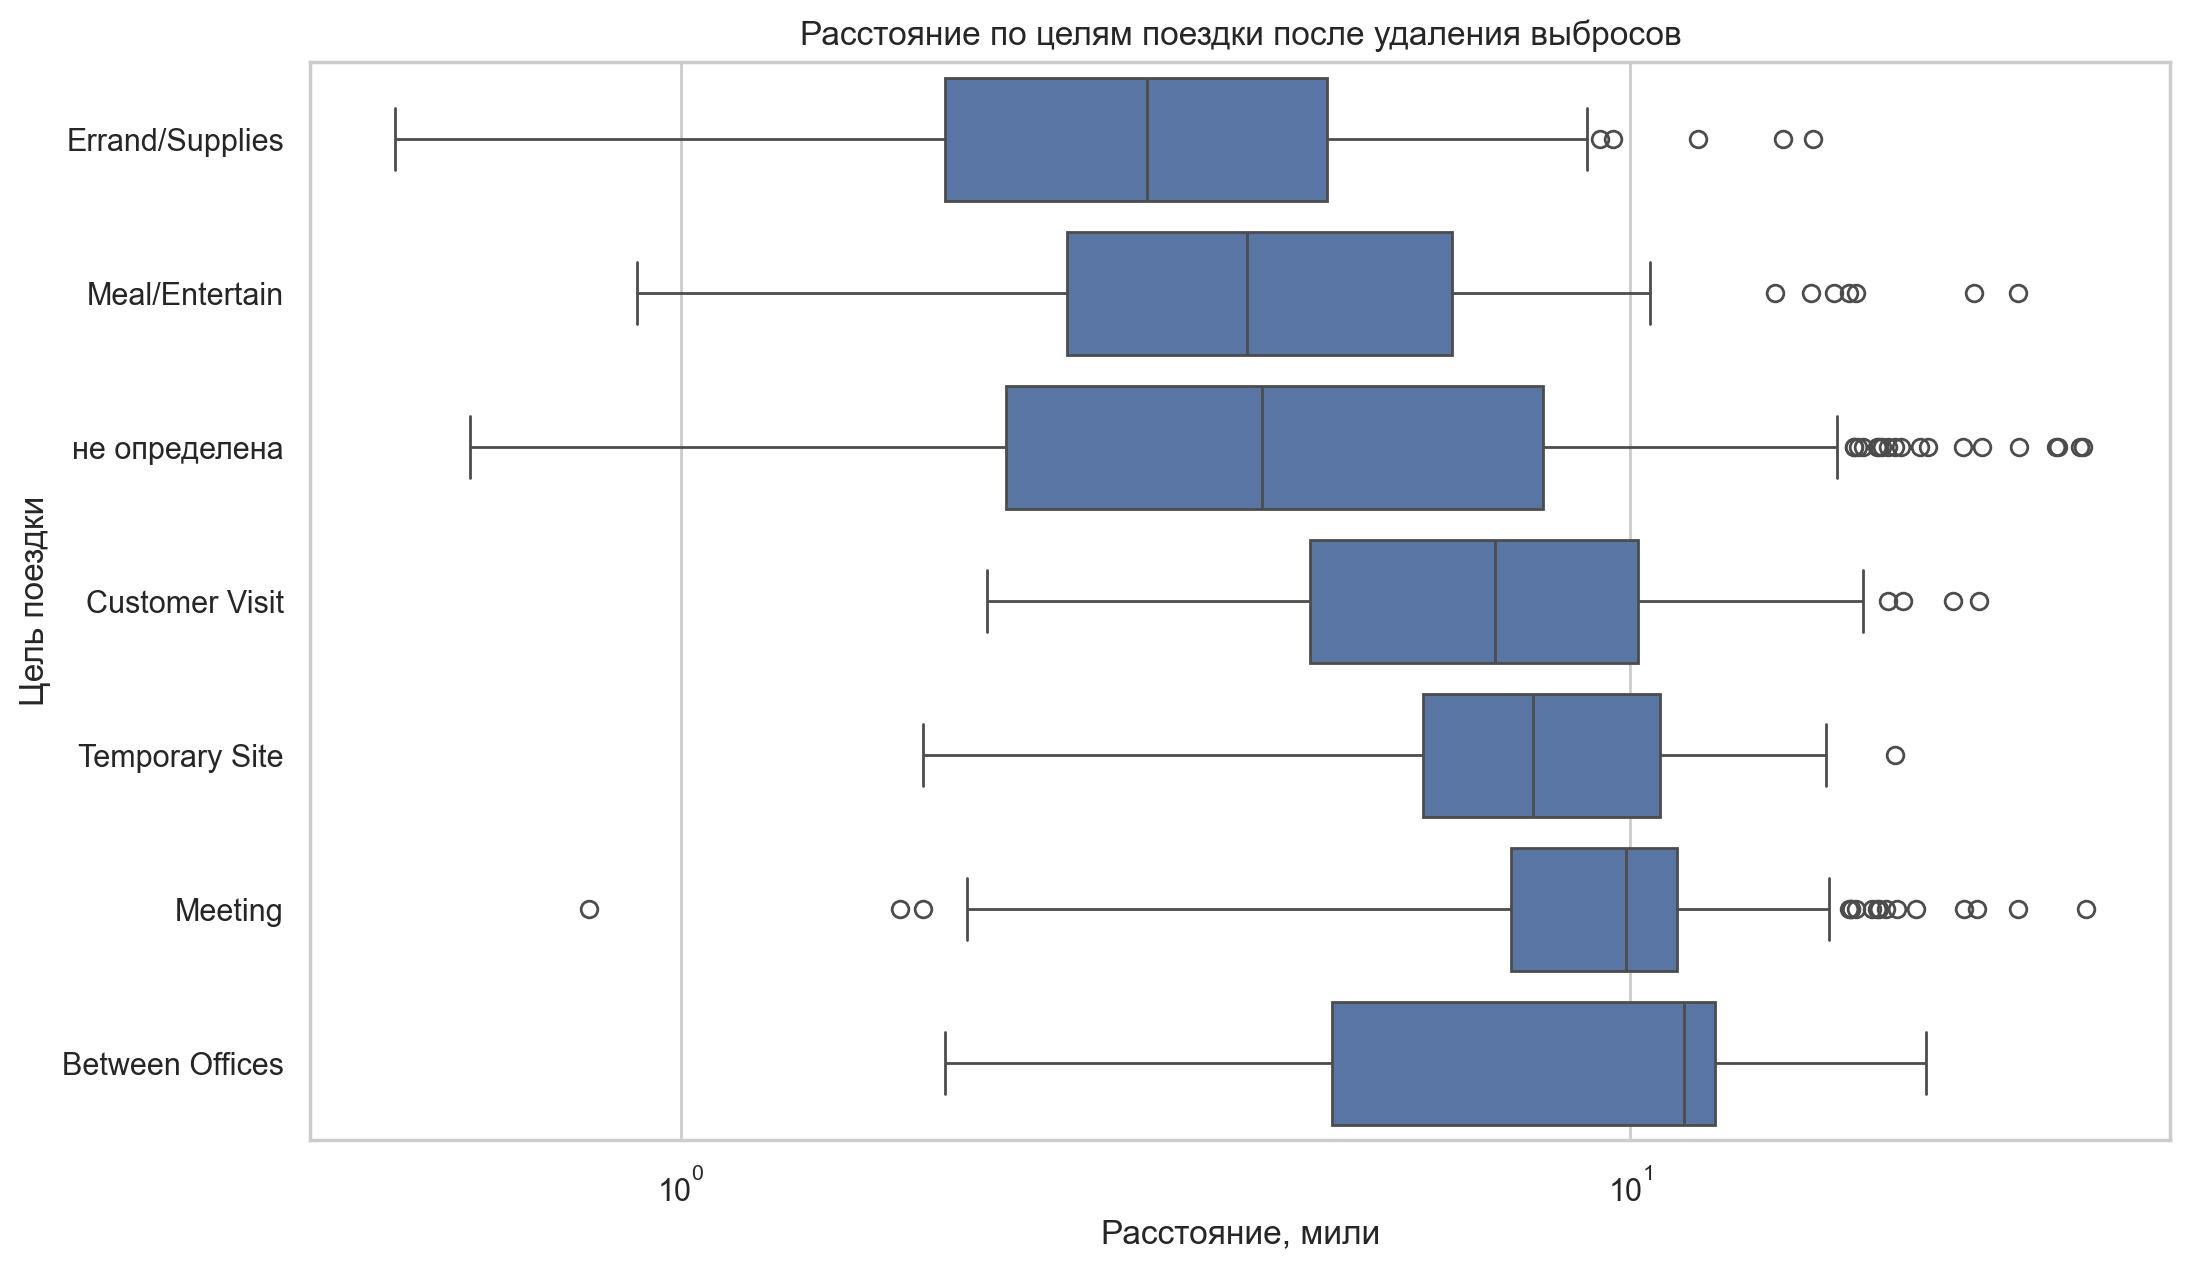

In [31]:
trips_per_purpose = price_cleaned['PURPOSE'].value_counts()
frequent_purposes = trips_per_purpose[trips_per_purpose >= 5].index
frequent_trips = price_cleaned[price_cleaned['PURPOSE'].isin(frequent_purposes)]
median_miles = frequent_trips.groupby('PURPOSE')['MILES'].median()
purpose_order = median_miles.sort_values().index

fig, ax = plt.subplots(figsize=(12, 7))
sns.boxplot(data=frequent_trips, x='MILES', y='PURPOSE', order=purpose_order,
            ax=ax)
ax.set(xscale='log', xlabel=LABELS['MILES'], ylabel='Цель поездки',
       title='Расстояние по целям поездки после удаления выбросов')
plt.show()

Сильнее всего изменились цели, у которых были междугородние поездки. У Customer Visit удалено 19 поездок из 92, максимум упал с 310 до 23 миль, а среднее — с 21.9 до 8.1 при медиане 7.2. У Meeting среднее снизилось с 15.6 до 10.0 при медиане 9.9. Теперь средние у этих целей почти равны медианам. Вывод из задания 2, что дальше всего ездят к клиентам, держался только на нескольких поездках в другой город: без них Customer Visit по медиане оказался ниже Temporary Site.

Деление на короткие цели (поручения и обеды) и длинные сохранилось. Выбросы справа остались почти у всех целей, а у Meeting их даже стало больше — 17 вместо 14: ящик сузился, и границы сдвинулись к нему. Как и с категориями дальности, у каждой цели свои квартили, и общая граница по стоимости их выбросы не убирает.

## 12. Удаление выбросов стоимости по категориям поездки

В разделе 11 границы выбросов считались по всем поездкам сразу. Здесь та же процедура выполняется отдельно для деловых и личных поездок: у каждой категории свои квартили и свои границы. Удаление снова начинается с исходных 1080 поездок.

In [32]:
cleaned_parts = []
for category, group in trips.groupby('CATEGORY'):
    cleaned, steps = remove_outliers(group, 'PRICE')
    cleaned_parts.append(cleaned)
    print(f'{category}: итераций {len(steps)}, '
          f'осталось {len(cleaned)} из {len(group)}')
    display(steps.round(0))

category_cleaned = pd.concat(cleaned_parts)
print(f'Всего осталось поездок: {len(category_cleaned)} из {len(trips)}')

Business: итераций 4, осталось 908 из 1003


,Поездок,Нижняя граница,Верхняя граница,Удалено
Итерация,,,,
1,1003,-938.0,4462.0,56
2,947,-600.0,3900.0,20
3,927,-490.0,3714.0,10
4,917,-380.0,3532.0,9


Personal: итераций 3, осталось 66 из 77


,Поездок,Нижняя граница,Верхняя граница,Удалено
Итерация,,,,
1,77,-638.0,3562.0,7
2,70,-189.0,2814.0,3
3,67,-226.0,2778.0,1


Всего осталось поездок: 974 из 1080


Для деловых поездок понадобилось 4 итерации, для личных — 3. Деловые поездки — это 93 % таблицы, поэтому их границы почти совпадают с общими из раздела 11, и остались ровно те же 908 деловых поездок. Разница только в личных поездках. Они дешевле, и последняя граница у них 2778, а в разделе 11 была 3527. Поэтому удалены ещё 4 личные поездки стоимостью от 2813 до 3416, которые при общем удалении остались. Всего осталось 974 поездки.

Строю общую диаграмму размаха: деловые, личные и все оставшиеся поездки вместе.

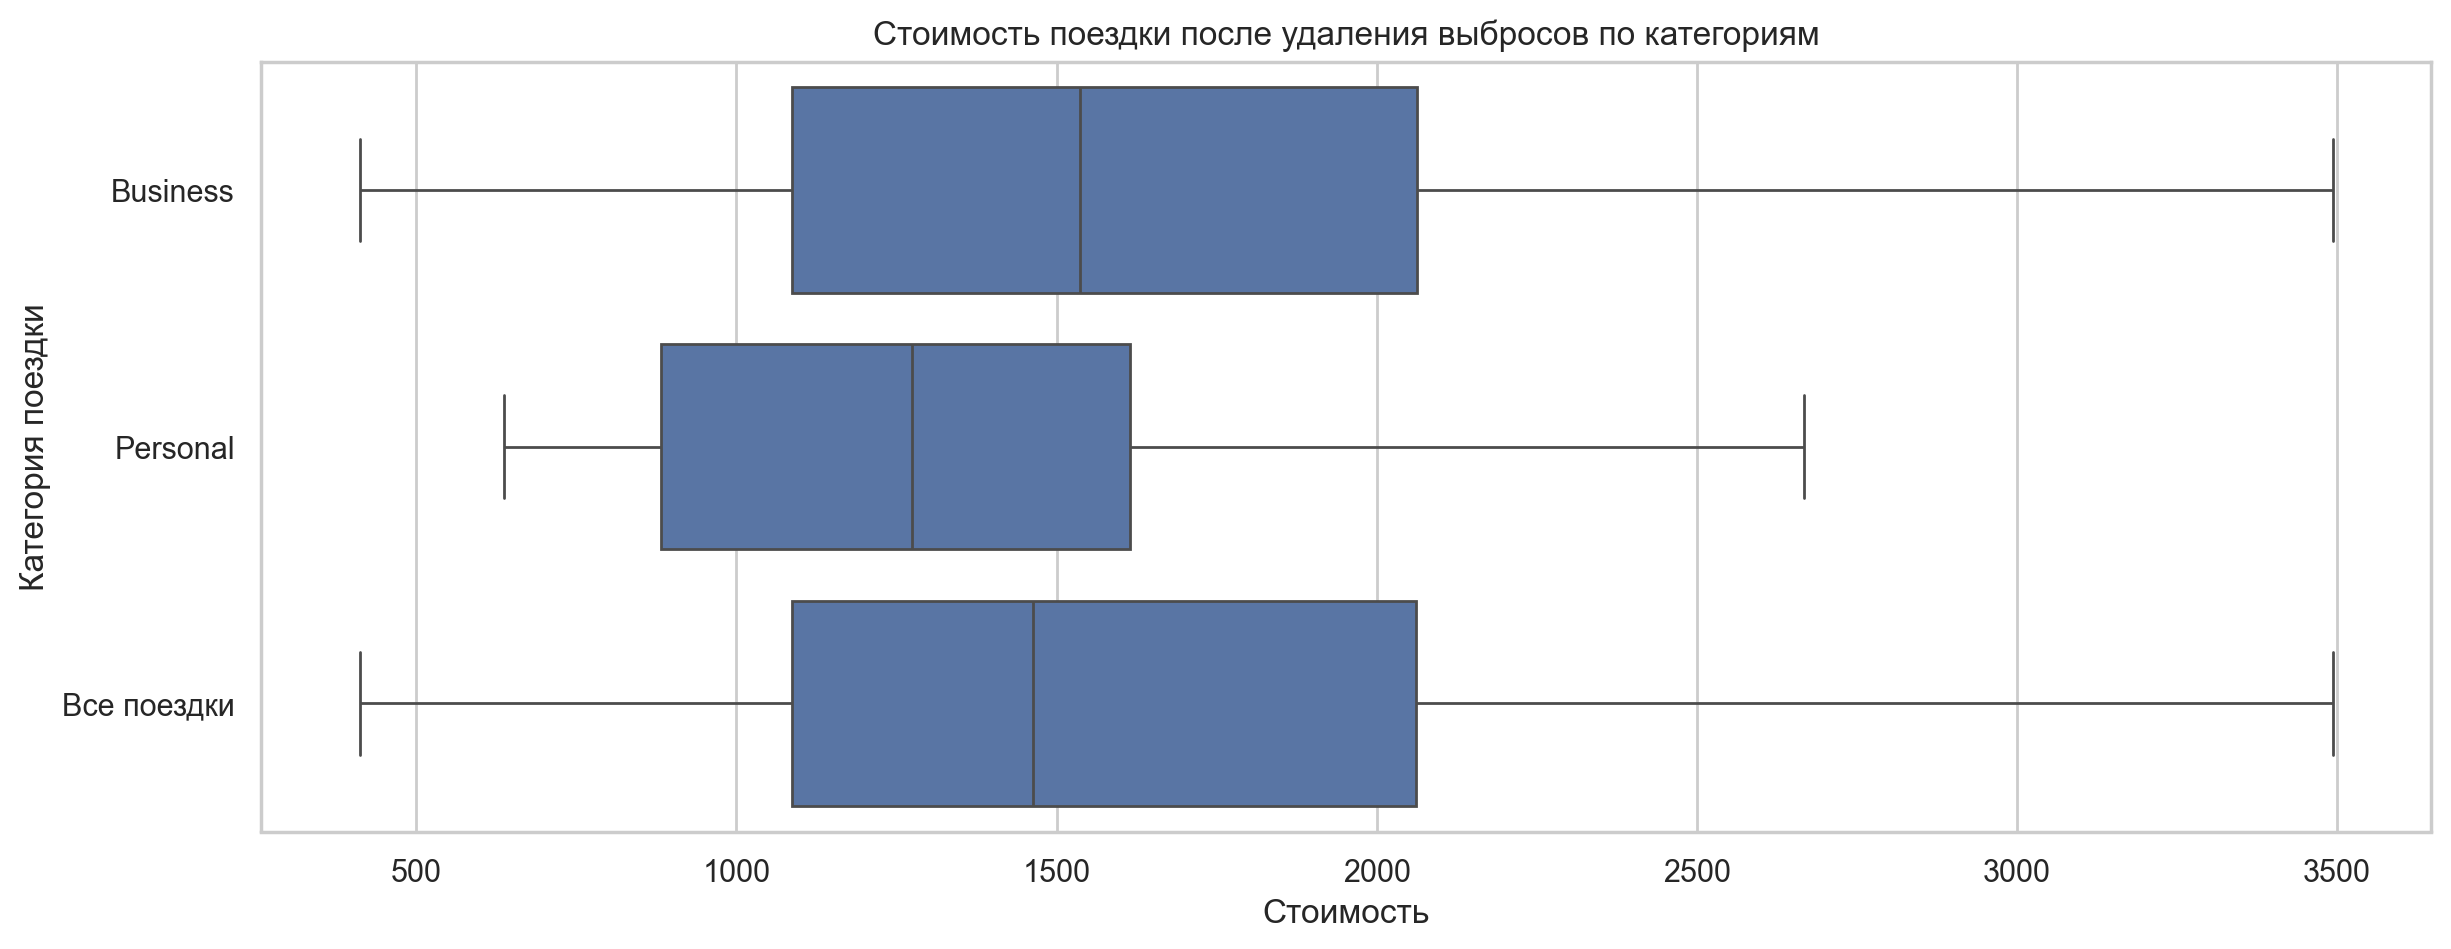

In [33]:
boxes = pd.concat([category_cleaned,
                   category_cleaned.assign(CATEGORY='Все поездки')])

fig, ax = plt.subplots(figsize=(14, 5))
sns.boxplot(data=boxes, x='PRICE', y='CATEGORY', ax=ax)
ax.set(xlabel=LABELS['PRICE'], ylabel='Категория поездки',
       title='Стоимость поездки после удаления выбросов по категориям')
plt.show()

In [34]:
boxes.groupby('CATEGORY')['PRICE'].describe().round(0)

,count,mean,std,min,25%,50%,75%,max
CATEGORY,,,,,,,,
Business,908.0,1637.0,726.0,412.0,1087.0,1536.0,2063.0,3493.0
Personal,66.0,1353.0,534.0,637.0,882.0,1274.0,1614.0,2667.0
Все поездки,974.0,1618.0,718.0,412.0,1086.0,1463.0,2062.0,3493.0


Выбросов на диаграмме нет ни у одной категории, ни у всех поездок вместе. Личные поездки дешевле деловых: медиана 1274 против 1536, ящик личных поездок (882–1614) сдвинут влево и перекрывается с ящиком деловых (1087–2063) только на участке 1087–1614. Эта разница была и до удаления выбросов (медианы 1462 и 1612), но на диаграммах её закрывал хвост до 25 000.

Ящик всех поездок почти совпадает с ящиком деловых, потому что деловых поездок в 14 раз больше. Только медиана всех поездок ниже, 1463: личные поездки сдвигают её влево.

Удаление по категориям убрало на 4 поездки больше, чем общее, и все они личные. Если категории нужно сравнивать между собой, выбросы лучше удалять внутри каждой категории: иначе границу для всех задают деловые поездки, и для личных она оказывается слишком широкой.

## 13. Выводы

Исследован набор данных `drivers.csv` — поездки в такси за 2016 год с расстоянием, длительностью, скоростью, стоимостью, категорией и целью.

Предобработка:

- основная предобработка выполнена в ЛР1: названия столбцов приведены к одному виду, пропуски в цели поездки заменены на «не определена», удалены 4 поездки с нулевой длительностью, типы столбцов исправлены. Обработанная таблица из 1095 поездок загружена из `data/drivers_clean.csv`;
- дополнительно удалены 15 поездок со скоростью больше 100 миль/ч — у них ошибочная длительность. Осталось 1080 поездок. Несколько коротких поездок со скоростью 80–90 миль/ч, вероятно, тоже ошибочны, но порог 100 миль/ч их не отсёк.

Результаты:

- расстояние, длительность и стоимость распределены с сильным хвостом вправо, в логарифмической шкале их распределения почти симметричны. Типичная поездка — около 6 миль и 17 минут, дальних поездок (больше 50 миль) всего 25;
- стоимость линейно зависит от длительности: около 335 за посадку и 75 за минуту, корреляция 1.00. От расстояния стоимость зависит только через время;
- расстояние сильно связано с длительностью и стоимостью (корреляция 0.85–0.87), со скоростью — умеренно (0.48 по Пирсону, 0.62 по Спирмену). Дальние поездки быстрее, так как идут по трассе. Отрицательных связей нет;
- 93 % поездок деловые. Скорость деловых и личных поездок почти не различается;
- у 45 % поездок цель не указана. Из известных целей чаще всего встречи, обеды и поручения;
- по расстоянию цели делятся на короткие (поручения и обеды, медиана 3–4 мили) и длинные (встречи, визиты к клиентам, поездки между офисами, медиана 8–12 миль). Средние расстояния у встреч и визитов к клиентам завышены редкими междугородними поездками, медиана описывает эти цели точнее.

Дополнительные задания:

- кроме правила Фридмана — Диакониса проверены формулы Стёрджеса, квадратного корня, Райса, Скотта и Доана. Первые три зависят только от числа наблюдений и дают 12, 33 и 21 bins для любого признака. В обычной шкале ни одна формула не даёт читаемой гистограммы расстояния, длительности и стоимости — мешает длинный хвост. В логарифмической шкале лучше всего выглядят гистограммы по Райсу, Скотту и Фридману — Диаконису (19–29 bins), а для `TIME` из-за целых минут лучше Райс и Скотт;
- выбросы стоимости исчезли после 4 итераций удаления по правилу 1.5 · IQR. Удалено 102 поездки, все длиннее 42 минут. Повторное удаление срезает хвост распределения: дальних поездок осталось 68 из 144, среднее расстояние у Customer Visit упало с 21.9 до 8.1 мили. На диаграммах размаха по группам выбросы остались, потому что у каждой группы свои квартили;
- при удалении выбросов стоимости отдельно по категориям понадобилось 4 итерации для деловых поездок и 3 для личных, осталось 974 поездки. На общей диаграмме выбросов нет, личные поездки дешевле деловых: медиана 1274 против 1536.